# Optimizing Heat Flux Density for Solar Tower Power Plants: revised implementation

Reference implementation of the convex aim-point correction method of

> D. Sajedi-Hosseini and X. Shen, *"Optimizing Heat Flux Density for Solar Tower Power Plants:
> A Novel HFLCAL Linearization Approach"*, Renewable Energy (manuscript RENE-D-26-10794, revised).

Slow structural drift (foundation settlement, soil erosion, mechanical wear) misaligns heliostats.
On a cylindrical receiver surrounded by a circular field, the displaced aim-points converge onto one
meridian and create a hot spot that can exceed the allowable flux density (AFD). Linearizing the
HFLCAL flux model about the misaligned aim-points turns the correction into a convex quadratic program
(QP) in which the AFD is a hard constraint.

**What this notebook contains.** Sections 1-3 define the model, the metaheuristic baselines and shared
helpers. Section 4 reproduces the results of the first submission. Sections 5-16 produce every result
of the revised manuscript:

| Section | Content | Reviewer comment |
|---|---|---|
| 5 | Headline case: drift converging on the North meridian; Table 2 | 1.4 |
| 6 | Validity of the linearization | 1.1 |
| 7 | Allowable-flux-density profile of Sánchez-González et al. (2017) | 1.2 |
| 8 | Uniformity-interception trade-off, defocusing counterfactual | 1.3 |
| 9 | Operating conditions over the day and the year | 1.5, 1.8 |
| 10 | Phase-1/Phase-2 decoupling, refined | 1.5 |
| 11 | Errors in the misalignment estimate | 1.6 |
| 12 | Timing for online use | 1.9 |
| 13 | Input-parameter and focal-length sensitivity | 2.1, 2.6 |
| 14 | Comparison with published values; ray-tracing round-robin benchmark | 2.6 |
| 15 | Annual clear-sky evaluation; interpolation checked against direct solves | 2.3, 2.7, 1.3 |
| 16 | Scaling of the baselines (groups, budget, seeds) | 1.4 |

**How to run.** Run all cells from top to bottom in the `solar-main` environment
(`environment.yml`). A complete run takes about eight hours on a 4-core laptop CPU, six of them in Section 16, which is
placed last; set `RUN['scaling'] = False` to skip it. Every number quoted in the manuscript is collected in the
dictionary `R` and written to `results_R1.json`; figures are written to `figures/`.

**Reproducibility.** The flux model, the QP and all sweeps are deterministic (all random draws are
seeded). The metaheuristic baselines are budgeted in wall-clock time, so their figures depend slightly
on the hardware; the machine used is printed in Section 0.

## 0. Setup

In [1]:
import json, os, platform, time
import numpy as np
import scipy.sparse as sp
import matplotlib.pyplot as plt

plt.rcParams.update({
    'figure.dpi': 110, 'font.size': 13, 'axes.titlesize': 14, 'axes.labelsize': 14,
    'xtick.labelsize': 12, 'ytick.labelsize': 12, 'legend.fontsize': 11,
    'mathtext.fontset': 'stix', 'font.family': 'STIXGeneral'})

RUN = dict(
    psi_headline=90.0,        # convergence meridian of the structural drift [deg]: 90 = North
    seeds=[1, 2, 3, 4, 5],    # seeds of the metaheuristic baselines
    scaling=True,             # Section 16 (several hours)
    annual=True,              # Section 15
)
FIGDIR = 'figures'; os.makedirs(FIGDIR, exist_ok=True)
R = {}                        # every number quoted in the manuscript


def save_results():
    with open('results_R1.json', 'w') as f:
        json.dump(R, f, indent=1, default=float)


def savefig(fig, name):
    fig.savefig(os.path.join(FIGDIR, name), dpi=400, bbox_inches='tight')


R['machine'] = dict(cpu=platform.processor(), system=platform.platform(), python=platform.python_version(),
                    cores=os.cpu_count())
print(R['machine'])

{'cpu': 'Intel64 Family 6 Model 142 Stepping 10, GenuineIntel', 'system': 'Windows-11-10.0.26200-SP0', 'python': '3.12.15', 'cores': 8}


## 1. Model

One class, `Case`, holds everything for one operating point: sun position, heliostat field, per-heliostat
optics, unwrapped-cylinder receiver, nominal aiming, structural misalignment, the linearized model and
the convex QP.

* **Sun position.** Declination (Cooper) and hour angle give the sun vector for any day and solar time.
* **Field.** A radial-staggered concentric-ring reconstruction of the 2,650-heliostat Gemasolar field
  (exact as-built coordinates are not public).
* **Optics (HFLCAL).** Slant range $D_k$, incidence angle $\beta_k$, power $P_H=I_D A_H\cos\beta_k f_{at}\eta_{ref}$
  and beam spread $\sigma_{HF,k}^2 = D_k^2(\sigma_{sun}^2+\sigma_{bq}^2+\sigma_{ast}^2+\sigma_t^2)/\cos\omega_{rec,k}$,
  with $\sigma_{bq}=2\sigma_{slope}$ and facets canted on axis ($f=D_k$, so $H_t=w_s=d(1-\cos\beta_k)$).
  Blocking and shading are neglected ($f_{bs}=1$).
* **Receiver.** The cylinder is unwrapped into a periodic $128\times128$ grid; circumferential distances
  are taken the shorter way around.
* **Nominal aiming.** Aiming-factor strategy: each heliostat aims at the meridian facing it, alternately
  above and below the equator at $|y^0_{t,k}| = H_{rec}/2 - f_{aim}\sigma_{HF,k}$; $f_{aim}$ is bisected so that
  the nominal peak is 95 % of the AFD.
* **Misalignment.** The residual displacement $\Delta_{mech}=1$ m of every heliostat is directed as
  $(-\sin(\theta_k-\psi), \cos(\theta_k-\psi))$ on the unwrapped receiver, so that aim-points converge onto the
  meridian at azimuth $\psi$ ($\theta_k$ = heliostat azimuth, counterclockwise from East).
* **Linearized model and QP.** First-order sensitivities (Eq. 10), the QP of Eq. (12) with the correction box,
  the on-receiver bound and a (scalar or per-pixel) flux cap, solved with Clarabel; the cap is imposed by
  constraint generation on the pixels that can approach it. Metrics are always evaluated on the exact flux.

In [2]:
# ----------------------------------------------------------------------------- plant
GEMASOLAR = dict(
    H_T=120.0, A_H=115.7, D_rec=8.5, H_rec=10.5, phi_lat=37.56, I_D=0.95,
    sigma_sun=2.73e-3, sigma_slope=2.6e-3, sigma_t=2.1e-3, H_M=5.0, eta_ref=0.94,
    r_min=40.0, r_max=600.0, F_max_kw=1000.0, K=2650,
)

DEFAULT_CFG = dict(
    n_h=128, n_v=128, doy=80, solar_hour=12.0,
    delta_max=1.0, nominal_peak_target=0.95, f_aim=None,     # f_aim=None -> bisection
    mis_model='displacement', mis_displacement_scale_m=1.0, mis_residual_angle_mrad=2.0,
    psi_deg=0.0,                                             # convergence meridian (0 = East, notebook)
    qp_tol=1e-4, cap_prune=0.8, cap_stride=2, aim_margin_sigma=0.0,
    use_atm_attenuation=True, focal='slant', focal_m=None,  # focal='slant' -> f = D (notebook)
    dni_override=None,
)


def sun_vector(doy, solar_hour, phi_lat):
    """Sun unit vector (East, North, Up) from declination (Cooper) and hour angle.
    At solar_hour = 12 this equals the notebook's noon vector exactly."""
    dec = np.deg2rad(23.45*np.sin(np.deg2rad(360.0*(284 + doy)/365.0)))
    w = np.deg2rad(15.0*(solar_hour - 12.0))
    phi = np.deg2rad(phi_lat)
    S = np.array([-np.cos(dec)*np.sin(w),
                  np.cos(phi)*np.sin(dec) - np.sin(phi)*np.cos(dec)*np.cos(w),
                  np.sin(phi)*np.sin(dec) + np.cos(phi)*np.cos(dec)*np.cos(w)])
    return S/np.linalg.norm(S), np.degrees(dec)


def ring_field(K, r_min, r_max):
    """Notebook cell 9: radial-staggered concentric rings."""
    n_rings = max(1, int(round(np.sqrt(K/3.0))))
    radii = np.linspace(r_min, r_max, n_rings)
    counts = np.maximum(1, np.round(radii/radii.sum()*K).astype(int))
    while counts.sum() > K: counts[np.argmax(counts)] -= 1
    while counts.sum() < K: counts[np.argmin(counts)] += 1
    Xl, Yl = [], []
    for i, (R, c) in enumerate(zip(radii, counts)):
        off = (np.pi/c)*(i % 2)
        ang = np.linspace(0, 2*np.pi, c, endpoint=False) + off
        Xl.append(R*np.sin(ang)); Yl.append(R*np.cos(ang))
    return np.concatenate(Xl), np.concatenate(Yl)


class Case:
    """Everything that the notebook keeps as module-level state, for one operating point."""

    def __init__(self, plant=None, **cfg):
        P = dict(GEMASOLAR); P.update(plant or {})
        C = dict(DEFAULT_CFG); C.update(cfg)
        self.P, self.C = P, C
        K = P['K']; self.K = K
        self.R_rec = P['D_rec']/2.0; self.C_circ = np.pi*P['D_rec']; self.H_rec = P['H_rec']
        n_h, n_v = C['n_h'], C['n_v']; self.n_h, self.n_v = n_h, n_v
        # sun
        self.S, self.declination = sun_vector(C['doy'], C['solar_hour'], P['phi_lat'])
        self.elevation = np.degrees(np.arcsin(self.S[2]))
        # field
        self.X_H, self.Y_H = ring_field(K, P['r_min'], P['r_max'])
        self.D_M = np.hypot(self.X_H, self.Y_H)
        # optics (cell 11)
        helio = np.stack([self.X_H, self.Y_H, np.full(K, P['H_M'])], axis=1)
        vec = np.array([0, 0, P['H_T']])[None, :] - helio
        D = np.linalg.norm(vec, axis=1); self.D = D
        Tu = vec/D[:, None]
        N = self.S[None, :] + Tu; N /= np.linalg.norm(N, axis=1, keepdims=True)
        cos_beta = np.clip(N @ self.S, -1, 1); self.cos_beta = cos_beta
        self.beta = np.arccos(cos_beta)
        f_focal = D.copy() if C['focal'] == 'slant' else np.full(K, float(C['focal_m']))
        d_dim = np.sqrt(P['A_H'])
        self.f_at = (np.clip(0.99321 - 1.176e-4*D + 1.97e-8*D**2, 0.0, 1.0)
                     if C['use_atm_attenuation'] else np.ones(K))
        I_D = P['I_D'] if C['dni_override'] is None else C['dni_override']
        self.I_D = I_D
        self.P_H = I_D*P['A_H']*cos_beta*self.f_at*P['eta_ref']*1.0          # f_bs = 1
        H_t = d_dim*np.abs(D/f_focal - cos_beta); w_s = d_dim*np.abs(D/f_focal*cos_beta - 1)
        self.sigma_ast = np.sqrt(0.5*(H_t**2 + w_s**2))/(4*D)
        sigma_bq = 2*P['sigma_slope']
        self.cos_w_rec = np.clip((self.D_M - self.R_rec)/D, 0.05, 1.0)
        self.sigma_HF = np.sqrt(D**2*(P['sigma_sun']**2 + sigma_bq**2 + self.sigma_ast**2
                                      + P['sigma_t']**2)/self.cos_w_rec)
        # receiver grid (cell 13)
        ex = np.linspace(-self.C_circ/2, self.C_circ/2, n_h+1); ey = np.linspace(-self.H_rec/2, self.H_rec/2, n_v+1)
        self.x_c = 0.5*(ex[:-1] + ex[1:]); self.y_c = 0.5*(ey[:-1] + ey[1:])
        Xg, Yg = np.meshgrid(self.x_c, self.y_c)
        self.xpix, self.ypix = Xg.ravel(), Yg.ravel(); self.n_pixels = self.xpix.size
        self.pixel_area = (self.C_circ/n_h)*(self.H_rec/n_v)
        self.theta_h = np.arctan2(self.Y_H, self.X_H)
        self.x_face = self.circ_dx(self.R_rec*self.theta_h, 0.0)
        self.pref = self.P_H/(2*np.pi*self.sigma_HF**2); self.inv2s2 = 1.0/(2*self.sigma_HF**2)
        self.F_max_scalar = P['F_max_kw']
        # nominal aiming-factor strategy
        self.x0_t = self.x_face.copy()
        self.s_k = np.where(np.arange(K) % 2 == 0, 1.0, -1.0)
        if C['f_aim'] is None:
            target = C['nominal_peak_target']*self.F_max_scalar
            lo, hi = 0.3, 4.0
            for _ in range(40):
                mid = 0.5*(lo + hi)
                if self.flux_map(self.x0_t, self._aim_y(mid)).max() > target: hi = mid
                else: lo = mid
            self.f_aim = 0.5*(lo + hi)
        else:
            self.f_aim = float(C['f_aim'])
        self.y0_t = self._aim_y(self.f_aim)
        self.F_nominal = self.flux_map(self.x0_t, self.y0_t)
        self.illum_mask = self.F_nominal > 0.05*self.F_nominal.max()
        # structural misalignment (cell 15, generalised to meridian psi)
        self.set_misalignment(C['psi_deg'])

    # ------------------------------------------------------------------ basics
    def circ_dx(self, a, b):
        d = a - b
        return d - self.C_circ*np.round(d/self.C_circ)

    def _aim_y(self, f):
        return self.s_k*np.maximum(self.H_rec/2.0 - f*self.sigma_HF, 0.0)

    def gauss_profiles(self, x0, y0):
        dxc = self.circ_dx(self.x_c[None, :], x0[:, None])
        dyc = self.y_c[None, :] - y0[:, None]
        Gx = np.exp(-(dxc*dxc)*self.inv2s2[:, None])
        Gy = np.exp(-(dyc*dyc)*self.inv2s2[:, None])
        return Gx, Gy, dxc, dyc

    def flux_map(self, x0, y0):
        Gx, Gy, _, _ = self.gauss_profiles(x0, y0)
        return ((Gy*self.pref[:, None]).T @ Gx).ravel()

    def interception(self, F):
        return float(F.sum()*self.pixel_area/self.P_H.sum())

    def uniformity(self, F):
        Fi = F[self.illum_mask]
        return float(np.std(Fi)/np.mean(Fi))

    def metrics(self, F, F_max=None):
        Fm = self.F_max_scalar if F_max is None else F_max
        ratio = F/Fm
        return dict(peak=float(F.max()), cv=self.uniformity(F), eta_int=100*self.interception(F),
                    P_int_MW=float(F.sum()*self.pixel_area/1e3), mean=float(F.mean()),
                    max_ratio_to_afd=float(np.max(ratio)))

    # ------------------------------------------------------------------ misalignment
    def displacement_field(self, psi_deg, scale=None):
        C = self.C
        if C['mis_model'] == 'angle':
            Dk = self.D*np.tan(C['mis_residual_angle_mrad']*1e-3)
        else:
            Dk = np.full(self.K, C['mis_displacement_scale_m'] if scale is None else scale)
        psi = np.deg2rad(psi_deg)
        return -Dk*np.sin(self.theta_h - psi), Dk*np.cos(self.theta_h - psi), Dk

    def set_misalignment(self, psi_deg):
        self.psi_deg = psi_deg
        self.dmech_x, self.dmech_y, self.Dmech_k = self.displacement_field(psi_deg)
        self.Dmech_mag = float(self.Dmech_k.mean())
        self.x0_mis = self.x0_t + self.dmech_x
        self.y0_mis = self.y0_t + self.dmech_y
        self.F_perturbed = self.flux_map(self.x0_mis, self.y0_mis)

    # ------------------------------------------------------------------ linearised model (cell 17)
    def build_sensitivity(self, x0m, y0m):
        Gx, Gy, dxc, dyc = self.gauss_profiles(x0m, y0m)
        inv_s2 = (2*self.inv2s2)[:, None]
        Gxp = self.pref[:, None]*Gx
        Gxdp = Gxp*dxc*inv_s2
        Gyd = Gy*dyc*inv_s2
        F0 = (Gy.T @ Gxp).ravel()
        return F0, Gy, Gyd, Gxp, Gxdp

    def sens_cols(self, S_, k):
        _, Gy, Gyd, Gxp, Gxdp = S_
        return np.outer(Gy[k], Gxdp[k]).ravel(), np.outer(Gyd[k], Gxp[k]).ravel()

    def fd_check(self, kp, eps=1e-4):
        S_ = self.build_sensitivity(self.x0_mis, self.y0_mis)
        Axk, Ayk = self.sens_cols(S_, kp)
        xp = self.x0_mis.copy(); xp[kp] += eps
        fdx = (self.flux_map(xp, self.y0_mis) - self.F_perturbed)/eps
        yp = self.y0_mis.copy(); yp[kp] += eps
        fdy = (self.flux_map(self.x0_mis, yp) - self.F_perturbed)/eps
        mx = np.abs(Axk) > 1e-6; my = np.abs(Ayk) > 1e-6
        return (float((np.abs(fdx[mx]-Axk[mx])/np.abs(Axk[mx])).max()),
                float(np.mean(np.sign(fdx[mx]) == np.sign(Axk[mx]))*100),
                float((np.abs(fdy[my]-Ayk[my])/np.abs(Ayk[my])).max()),
                float(np.mean(np.sign(fdy[my]) == np.sign(Ayk[my]))*100))

    def lin_flux(self, S_, z):
        F0_, Gy, Gyd, Gxp, Gxdp = S_
        K = self.K
        return F0_ + (Gy.T @ (z[:K, None]*Gxdp) + Gyd.T @ (z[K:, None]*Gxp)).ravel()

    # ------------------------------------------------------------------ QP (cell 19)
    def _qp_terms(self, S_, b):
        _, Gy, Gyd, Gxp, Gxdp = S_
        K = self.K
        H = np.empty((2*K, 2*K))
        H[:K, :K] = (Gy @ Gy.T)*(Gxdp @ Gxdp.T)
        H[K:, K:] = (Gyd @ Gyd.T)*(Gxp @ Gxp.T)
        Hxy = (Gy @ Gyd.T)*(Gxdp @ Gxp.T)
        H[:K, K:] = Hxy; H[K:, :K] = Hxy.T
        B = b.reshape(self.n_v, self.n_h)
        g = np.concatenate([((Gy @ B)*Gxdp).sum(1), ((Gyd @ B)*Gxp).sum(1)])
        return H, g

    def _cap_rows(self, S_, ps):
        _, Gy, Gyd, Gxp, Gxdp = S_
        vs, hs = ps // self.n_h, ps % self.n_h
        return np.hstack([(Gy[:, vs]*Gxdp[:, hs]).T, (Gyd[:, vs]*Gxp[:, hs]).T])

    def _clarabel_qp(self, H, g, lb, ub, Acap, rcap):
        import clarabel
        n = 2*self.K
        Pq = sp.triu(sp.csc_matrix(2.0*H), format='csc')
        Ieye = sp.eye(n, format='csc')
        blocks, rhs = [Ieye, -Ieye], [ub, -lb]
        if Acap is not None and Acap.shape[0]:
            blocks.append(sp.csc_matrix(Acap)); rhs.append(rcap)
        Acon = sp.vstack(blocks, format='csc')
        st = clarabel.DefaultSettings(); st.verbose = False
        if self.C['qp_tol'] is not None:
            st.tol_gap_rel = st.tol_gap_abs = st.tol_feas = self.C['qp_tol']
        t0 = time.time()
        sol = clarabel.DefaultSolver(Pq, -2.0*g, Acon, np.concatenate(rhs),
                                     [clarabel.NonnegativeConeT(Acon.shape[0])], st).solve()
        ok = str(sol.status) in ('Solved', 'AlmostSolved')
        return (np.asarray(sol.x) if ok else None), str(sol.status), time.time() - t0

    def bounds(self, y0m, delta_max=None, aim_margin_sigma=None):
        K = self.K
        dm = self.C['delta_max'] if delta_max is None else delta_max
        am = self.C['aim_margin_sigma'] if aim_margin_sigma is None else aim_margin_sigma
        y_edge = self.H_rec/2.0 - am*self.sigma_HF
        lb = np.concatenate([np.full(K, -dm), np.maximum(-dm, -y_edge - y0m)])
        ub = np.concatenate([np.full(K, dm), np.minimum(dm, y_edge - y0m)])
        off = lb[K:] > ub[K:]
        if off.any():
            pin = np.where(y0m[off] > 0, -dm, dm)
            lb[K:][off] = ub[K:][off] = pin
        return lb, ub

    def solve_qp(self, x0m, y0m, F_ref, F_max=None, delta_max=None, aim_margin_sigma=None,
                 z_offset=None, lb_ub=None):
        """Notebook solve_qp, generalised: F_max may be a per-pixel vector; z_offset lets a
        re-linearisation step expand about already-corrected aims while bounding the TOTAL
        correction (lb_ub given in total-correction coordinates)."""
        t0 = time.time(); timing = {}
        K = self.K
        Fm = self.F_max_scalar if F_max is None else F_max
        Fm_vec = np.broadcast_to(np.asarray(Fm, dtype=float), (self.n_pixels,))
        S_ = self.build_sensitivity(x0m, y0m); timing['sensitivity'] = time.time() - t0
        F0_ = S_[0]
        t1 = time.time(); H, g = self._qp_terms(S_, F_ref - F0_); timing['hessian'] = time.time() - t1
        if lb_ub is None:
            lb, ub = self.bounds(y0m, delta_max, aim_margin_sigma)
        else:
            lb, ub = lb_ub
            if z_offset is not None:
                lb, ub = lb - z_offset, ub - z_offset
        cap_mask = F0_ > self.C['cap_prune']*Fm_vec
        s_ = max(1, int(self.C['cap_stride']))
        thin = np.zeros((self.n_v, self.n_h), dtype=bool)
        thin[::s_, ::s_] = cap_mask.reshape(self.n_v, self.n_h)[::s_, ::s_]
        ps = np.where(thin.ravel())[0]
        zc, status, F_lin, t_solve = None, 'unsolved', None, 0.0
        rounds = 0
        for rounds in range(1, 4):
            Acap = self._cap_rows(S_, ps) if ps.size else None
            rcap = (Fm_vec - F0_)[ps] if ps.size else None
            z, status, ts = self._clarabel_qp(H, g, lb, ub, Acap, rcap); t_solve += ts
            if z is None:
                return dict(status=status, time=time.time()-t0, dx=None, dy=None, n_cap=int(ps.size),
                            timing=timing)
            zc = np.clip(z, lb, ub)
            F_lin = self.lin_flux(S_, zc)
            viol = np.where(cap_mask & (F_lin > Fm_vec*(1 + 1e-6)))[0]
            new = np.setdiff1d(viol, ps)
            if new.size == 0:
                break
            ps = np.union1d(ps, new)
        timing['solve'] = t_solve
        dt = time.time() - t0
        dxo, dyo = zc[:K], zc[K:]
        Fc = self.flux_map(x0m + dxo, y0m + dyo)
        lin_gap = float(np.linalg.norm(F_lin - Fc)/np.linalg.norm(Fc))
        step_sigma_min = float(max(np.abs(dxo).max(), np.abs(dyo).max())/self.sigma_HF.min())
        cap_exceed = float(max(0.0, np.max(Fc - Fm_vec)))
        timing['total'] = dt
        return dict(status=status, time=dt, dx=dxo, dy=dyo, obj=float(np.sum((F_lin - F_ref)**2)),
                    n_cap=int(ps.size), rounds=rounds, F_true=Fc, F_lin=F_lin,
                    J_true=float(np.sum((Fc - F_ref)**2)), peak=float(Fc.max()),
                    lin_gap=lin_gap, step_sigma_min=step_sigma_min, cap_exceed=cap_exceed,
                    aim_y_max=float(np.abs(y0m + dyo).max()), timing=timing)

    def scp_step(self, r, F_ref, F_max=None, trust=None):
        """One re-linearisation (SCP) step: expand about the corrected aims of r, keep the
        TOTAL correction inside the original box/on-receiver bounds, optionally within a
        trust region of half-width `trust` around r's correction."""
        K = self.K
        z_prev = np.concatenate([r['dx'], r['dy']])
        lb, ub = self.bounds(self.y0_mis)
        if trust is not None:
            lb = np.maximum(lb, z_prev - trust); ub = np.minimum(ub, z_prev + trust)
        r2 = self.solve_qp(self.x0_mis + r['dx'], self.y0_mis + r['dy'], F_ref, F_max,
                           z_offset=z_prev, lb_ub=(lb, ub))
        if r2['dx'] is None:
            return r2
        r2['dx'] = r2['dx'] + r['dx']; r2['dy'] = r2['dy'] + r['dy']
        return r2

    # ------------------------------------------------------------------ baselines (cells 21-22)
    def make_groups(self, n_groups, seed=1):
        from scipy.cluster.vq import kmeans2
        G = int(min(n_groups, self.K))
        if G >= self.K:
            return np.arange(self.K), self.K
        pts = np.column_stack([self.X_H, self.Y_H]).astype(float)
        _, labels = kmeans2(pts, G, minit='++', seed=seed)
        uniq = np.unique(labels); remap = {u: i for i, u in enumerate(uniq)}
        return np.array([remap[l] for l in labels]), len(uniq)

    def build_group_contrib(self, grp, G, n_grid):
        dm = self.C['delta_max']
        ox = np.linspace(-dm, dm, n_grid); oy = np.linspace(-dm, dm, n_grid)
        cand = np.array([(a, b) for a in ox for b in oy]); n_cand = cand.shape[0]
        contrib = np.zeros((G, n_cand, self.n_pixels), dtype=np.float32)
        ye = self.H_rec/2.0 - self.C['aim_margin_sigma']*self.sigma_HF
        for k in range(self.K):
            gxk = np.exp(-self.circ_dx(self.x_c[None, :], self.x0_mis[k] + ox[:, None])**2*self.inv2s2[k])
            yks = np.clip(self.y0_mis[k] + oy, -ye[k], ye[k])
            gyk = np.exp(-(self.y_c[None, :] - yks[:, None])**2*self.inv2s2[k])
            contrib[grp[k]] += (self.pref[k]*np.einsum('ah,bv->abvh', gxk, gyk)).reshape(n_cand, self.n_pixels).astype(np.float32)
        thg = np.array([np.arctan2(self.Y_H[grp == g].mean(), self.X_H[grp == g].mean()) for g in range(G)])
        xg0 = self.circ_dx(self.R_rec*thg, 0.0)
        yg0 = np.array([self.y0_mis[grp == g].mean() for g in range(G)])
        gxc = self.circ_dx(xg0[:, None] + cand[None, :, 0], 0.0)
        gyc = np.clip(yg0[:, None] + cand[None, :, 1], -self.H_rec/2, self.H_rec/2)
        return contrib, cand, n_cand, gxc, gyc

## 2. Metaheuristic baselines

Bounded ant-colony optimization (ACO, after Belhomme et al. 2014) and a bounded genetic algorithm with a
self-modifying repair (GA, after Besarati et al. 2014). Heliostats are clustered into $G$ position-based
groups that share one offset from a $5\times5$ candidate grid inside the same $\pm1$ m box. The AFD is
handled by a **feasibility-first ranking**: every feasible solution ranks above every infeasible one, and
infeasible solutions are ranked by their worst violation. The GA uses the population size of Besarati
et al. (100). Both are budgeted in wall-clock time; the contribution tensor shared by both is built once.

In [3]:
BIG = 1e18


def make_cost(case, F_ref, F_max, mode):
    Fm = np.broadcast_to(np.asarray(F_max, dtype=float), F_ref.shape)

    def cost(F):
        J = float(np.sum((F - F_ref)**2))
        viol = float(np.max(F - Fm))
        if mode == 'penalty':
            return J + (1e6 if viol > 0 else 0.0)
        if viol > 0:                                   # feasibility first
            return BIG*(1.0 + viol)
        return J
    return cost


def aco(case, contrib, budget_s, F_ref, F_max, mode='feasible_first', n_ants=30, rho=0.15,
        seed=1, t_offset=0.0, max_gen=10**7):
    G, n_cand, _ = contrib.shape
    rng = np.random.default_rng(seed)
    cost_fn = make_cost(case, F_ref, F_max, mode)
    pher = np.ones((G, n_cand)); best_cost, best = np.inf, None
    traj = []; t0 = time.time(); gen = 0; ar = np.arange(G)
    while (time.time() - t0) < budget_s and gen < max_gen:
        gen += 1
        cum = np.cumsum(pher/pher.sum(1, keepdims=True), axis=1)
        gbc, gb = np.inf, None
        for _ in range(n_ants):
            u = rng.random(G)
            ch = np.minimum((u[:, None] > cum).sum(1), n_cand - 1)
            F = contrib[ar, ch].sum(0, dtype=np.float64)
            c = cost_fn(F)
            if c < gbc: gbc, gb = c, ch
        if gbc < best_cost:
            best_cost, best = gbc, gb
            Fb = contrib[ar, best].sum(0, dtype=np.float64)
            traj.append((time.time() - t0 + t_offset, float(Fb.max()), case.uniformity(Fb)))
        pher *= (1 - rho)
        pher[ar, gb] += 1.0/(1 + min(gbc, 1e15)/case.n_pixels)
    return best, traj, gen


def ga(case, contrib, gxc, gyc, budget_s, F_ref, F_max, mode='feasible_first', pop_size=100,
       pc=0.9, pm=0.2, pmm=0.5, n_repair=8, seed=1, t_offset=0.0, max_gen=10**7):
    G, n_cand, _ = contrib.shape
    rng = np.random.default_rng(seed)
    cost_fn = make_cost(case, F_ref, F_max, mode)
    ar = np.arange(G); t0 = time.time(); traj = []

    def flux(ch):
        return contrib[ar, ch].sum(0, dtype=np.float64)

    def cost_of(ch):
        return cost_fn(flux(ch))

    def log_best(ch):
        Fb = flux(ch)
        traj.append((time.time() - t0 + t_offset, float(Fb.max()), case.uniformity(Fb)))

    def repair(ch, c0):
        for _ in range(n_repair):
            F = flux(ch)
            hot, cold = int(np.argmax(F)), int(np.argmin(F))
            dg = np.hypot(case.circ_dx(gxc[ar, ch], case.xpix[hot]), gyc[ar, ch] - case.ypix[hot])
            g_star = int(np.argmin(dg))
            dc = np.hypot(case.circ_dx(gxc[g_star], case.xpix[cold]), gyc[g_star] - case.ypix[cold])
            c_star = int(np.argmin(dc))
            if c_star == ch[g_star]: break
            trial = ch.copy(); trial[g_star] = c_star
            c1 = cost_of(trial)
            if c1 < c0: ch, c0 = trial, c1
            else: break
        return ch, c0

    pop = [rng.integers(0, n_cand, size=G) for _ in range(pop_size)]
    cost = [cost_of(ch) for ch in pop]
    # repair the initial population only while the budget lasts (matters for very fine groupings)
    for i in range(pop_size):
        if (time.time() - t0) >= budget_s:
            break
        pop[i], cost[i] = repair(pop[i], cost[i])
    b = int(np.argmin(cost)); best_ch, best_cost = pop[b].copy(), cost[b]; log_best(best_ch)
    gen = 0
    while (time.time() - t0) < budget_s and gen < max_gen:
        gen += 1
        children = []
        while len(children) < pop_size:
            i, j = rng.integers(0, pop_size, 2)
            a, b2 = pop[i].copy(), pop[j].copy()
            if rng.random() < pc:
                cpt = rng.integers(1, G)
                a[cpt:], b2[cpt:] = pop[j][cpt:], pop[i][cpt:]
            for ch in (a, b2):
                if rng.random() < pm:
                    mask = rng.random(G) < pmm
                    ch[mask] = rng.integers(0, n_cand, size=int(mask.sum()))
            children += [a, b2]
        children = children[:pop_size]
        ccost = [cost_of(ch) for ch in children]
        rep = [repair(ch, c) for ch, c in zip(children, ccost)]
        children = [r[0] for r in rep]; ccost = [r[1] for r in rep]
        pool = pop + children; pcost = cost + ccost
        newp, newc = [], []
        for _ in range(pop_size):
            i, j = rng.integers(0, len(pool), 2)
            w = i if pcost[i] <= pcost[j] else j
            newp.append(pool[w].copy()); newc.append(pcost[w])
        pop, cost = newp, newc
        b = int(np.argmin(cost))
        if cost[b] < best_cost:
            best_cost, best_ch = cost[b], pop[b].copy(); log_best(best_ch)
        if (time.time() - t0) >= budget_s:
            break
    return best_ch, traj, gen


def evaluate_assignment(case, cand, grp, best):
    """Exact (true nonlinear) flux of a group assignment, with aims clipped to the receiver."""
    off = cand[best[grp]]
    ye = case.H_rec/2.0 - case.C['aim_margin_sigma']*case.sigma_HF
    return case.flux_map(case.x0_mis + off[:, 0], np.clip(case.y0_mis + off[:, 1], -ye, ye))

## 3. Shared helpers

Metrics summaries, the defocusing counterfactual, the decoupling sweep, the Hottel clear-sky model, and
the AFD profile digitized from Sánchez-González et al. (2017), Fig. 18 (summer-solstice noon,
DNI = 930 W/m²). Their receiver has 18 panels; the salt enters at the north, splits into an east and a
west flow path, and follows a serpentine path (odd panels upward, even panels downward) to the south.

In [4]:
# AFD along the flow path, digitized from Sanchez-Gonzalez et al. (2017), Fig. 18 (mean of the east and
# west paths, which agree within 3 kW/m2). z_fp = 0 at the inlet (North), 94.5 m at the outlet (South).
AFD_Z = np.linspace(0.0, 94.5, 37)
AFD_KW = np.array([945.4, 945.4, 945.4, 945.4, 941.1, 936.6, 936.6, 930.8, 920.5, 915.4, 895.3, 872.1,
                   859.2, 843.7, 814.6, 785.2, 770.7, 755.2, 725.0, 692.2, 671.3, 651.7, 619.9, 589.6,
                   572.3, 553.7, 527.0, 499.3, 479.3, 459.3, 435.5, 414.0, 395.6, 376.0, 356.6, 337.3, 323.0])


def afd_shape(c):
    """Per-pixel AFD [kW/m2] of the digitized profile on the unwrapped receiver grid."""
    theta = np.degrees(c.xpix/c.R_rec)                    # receiver azimuth, CCW from East
    alpha = (90.0 - theta + 180.0) % 360.0 - 180.0        # azimuth from North, clockwise (East > 0)
    panel = np.minimum((np.abs(alpha)//20).astype(int), 8) + 1
    yrel = c.ypix + c.H_rec/2
    z_fp = 10.5*(panel - 1) + np.where(panel % 2 == 1, yrel, c.H_rec - yrel)
    return np.interp(z_fp, AFD_Z, AFD_KW)


def uniform_ref(c):
    return np.full(c.n_pixels, c.F_nominal.mean())


def qp_summary(c, r, F_max=None):
    if r['dx'] is None:
        return dict(status=r['status'], feasible=False)
    d = dict(status=r['status'], feasible=True, time=r['time'], lin_gap=r['lin_gap'], n_cap=r['n_cap'],
             step_sigma_min=r['step_sigma_min'], cap_exceed=r['cap_exceed'], aim_y_max=r['aim_y_max'])
    d.update(c.metrics(r['F_true'], F_max))
    return d


def angles_mrad(c, disp_m):
    a = np.arctan(disp_m/c.D)*1e3
    return float(a.min()), float(a.max())


def defocus(c, x0, y0, limit):
    """Operator counterfactual: defocus the heliostat with the largest flux at the current hot pixel
    until the peak is at most `limit`. Returns the number of heliostats removed and the flux."""
    Gx, Gy, _, _ = c.gauss_profiles(x0, y0)
    Gyp = Gy*c.pref[:, None]
    F = (Gyp.T @ Gx).ravel(); active = np.ones(c.K, bool); n = 0
    while F.max() > limit and n < c.K:
        p = int(np.argmax(F)); v, h = p // c.n_h, p % c.n_h
        contrib = Gyp[:, v]*Gx[:, h]; contrib[~active] = -1
        k = int(np.argmax(contrib)); active[k] = False; n += 1
        F -= np.outer(Gyp[k], Gx[k]).ravel()
    return n, F


def ratio_grid():
    return np.unique(np.concatenate([np.logspace(np.log10(0.01), np.log10(3.0), 25), [1.0]]))


def decoupling_sweep(c, zdx, zdy, ratios, n_seeds=5):
    """Deployed (fixed) correction versus a tracking residual eps, for random (per-heliostat) and
    coherent (field-wide) residual directions."""
    out = {}
    for mode in ('random', 'coherent'):
        cu, cd, pu, pd = (np.zeros((n_seeds, ratios.size)) for _ in range(4))
        for s in range(n_seeds):
            rng = np.random.default_rng(100 + s)
            if mode == 'random':
                ex, ey = rng.standard_normal(c.K), rng.standard_normal(c.K)
                nn = np.hypot(ex, ey); ex, ey = ex/nn, ey/nn
            else:
                th = rng.uniform(0, 2*np.pi); ex, ey = np.full(c.K, np.cos(th)), np.full(c.K, np.sin(th))
            for j, q in enumerate(ratios):
                em = q*c.Dmech_mag; xt, yt = c.x0_mis + em*ex, c.y0_mis + em*ey
                Fu = c.flux_map(xt, yt); Fd = c.flux_map(xt + zdx, yt + zdy)
                cu[s, j], cd[s, j], pu[s, j], pd[s, j] = c.uniformity(Fu), c.uniformity(Fd), Fu.max(), Fd.max()
        out[mode] = dict(cv_unc=cu, cv_dep=cd, pk_unc=pu, pk_dep=pd)
    return out


def coherent_mean_cv(c, zdx, zdy, q, n_seeds=5):
    v = []
    for s in range(n_seeds):
        th = np.random.default_rng(100 + s).uniform(0, 2*np.pi); em = q*c.Dmech_mag
        v.append(c.uniformity(c.flux_map(c.x0_mis + em*np.cos(th) + zdx, c.y0_mis + em*np.sin(th) + zdy)))
    return float(np.mean(v))


def pointing_budget(c, zdx, zdy, cv_design, ratios, cv_coh_mean, n_seeds=5):
    """Largest coherent residual (in units of Delta_mech) keeping the deployed CV within 10 % of its
    design value: bracketed on the sweep grid, then located by bisection."""
    ok = cv_coh_mean <= 1.10*cv_design
    if ok.all():
        return dict(threshold=float(ratios[-1]), bracket=[float(ratios[-1]), None])
    j = int(np.argmax(~ok))
    if j == 0:
        return dict(threshold=0.0, bracket=[0.0, float(ratios[0])])
    lo, hi = float(ratios[j-1]), float(ratios[j])
    for _ in range(18):
        mid = 0.5*(lo + hi)
        if coherent_mean_cv(c, zdx, zdy, mid, n_seeds) <= 1.10*cv_design: lo = mid
        else: hi = mid
    return dict(threshold=0.5*(lo + hi), bracket=[float(ratios[j-1]), float(ratios[j])])


def summarise_decoupling(c, sw, ratios, cv_design, thr):
    cd = sw['coherent']['cv_dep'].mean(0); cu = sw['coherent']['cv_unc'].mean(0); rd = sw['random']['cv_dep'].mean(0)
    j1 = int(np.argmin(np.abs(ratios - 1.0))); j3 = len(ratios) - 1
    def kept(j): return float((cu[j] - cd[j])/max(cu[j] - cv_design, 1e-12))
    eps_m = thr['threshold']*c.Dmech_mag
    beam = angles_mrad(c, eps_m)
    return dict(coh_dep_cv_at_1=float(cd[j1]), coh_unc_cv_at_1=float(cu[j1]), retained_at_1=kept(j1),
                rand_dep_cv_at_1=float(rd[j1]), coh_dep_cv_at_3=float(cd[j3]), coh_unc_cv_at_3=float(cu[j3]),
                retained_at_3=kept(j3), rand_dep_cv_at_3=float(rd[j3]),
                threshold_ratio=thr['threshold'], threshold_bracket=thr['bracket'], threshold_m=eps_m,
                threshold_beam_mrad=beam, threshold_mirror_mrad=(0.5*beam[0], 0.5*beam[1]),
                peak_dep_coh_max=float(sw['coherent']['pk_dep'].max()),
                peak_dep_rand_max=float(sw['random']['pk_dep'].max()))


def hottel_dni(doy, elevation_deg, alt_km=0.16):
    """Clear-sky beam irradiance of Hottel (1976) with mid-latitude climate corrections [kW/m2]."""
    if elevation_deg <= 0:
        return 0.0
    summer = 80 <= doy <= 266
    r0, r1, rk = (0.97, 0.99, 1.02) if summer else (1.03, 1.01, 1.00)
    a0 = r0*(0.4237 - 0.00821*(6 - alt_km)**2)
    a1 = r1*(0.5055 + 0.00595*(6.5 - alt_km)**2)
    k = rk*(0.2711 + 0.01858*(2.5 - alt_km)**2)
    G_on = 1367.0*(1 + 0.033*np.cos(2*np.pi*doy/365.0))
    return float(G_on*(a0 + a1*np.exp(-k/np.sin(np.deg2rad(elevation_deg))))/1000.0)

## 4. Reproduction of the first submission

With the drift converging on the East meridian ($\psi=0$), the configuration of the first submission,
the code must reproduce the submitted values: nominal peak 950.0 kW/m², misaligned peak 1039.1 kW/m²,
QP peak 720.5 kW/m², CV 0.1493, interception 83.8 %, model-plant gap 5.42 %.

In [5]:
c0 = Case(psi_deg=0.0)
r0 = c0.solve_qp(c0.x0_mis, c0.y0_mis, uniform_ref(c0))
R['repro_submission'] = dict(nominal_peak=float(c0.F_nominal.max()), perturbed_peak=float(c0.F_perturbed.max()),
                             qp_peak=r0['peak'], qp_cv=c0.uniformity(r0['F_true']),
                             qp_eta=100*c0.interception(r0['F_true']), lin_gap=r0['lin_gap'], n_cap=r0['n_cap'])
for k, v in R['repro_submission'].items():
    print(f'{k:<16}{v:>12.4f}')
del c0, r0

nominal_peak        950.0000
perturbed_peak     1039.1273
qp_peak             720.4645
qp_cv                 0.1493
qp_eta               83.8179
lin_gap               0.0542
n_cap              1071.0000


## 5. Headline case: drift converging on the North meridian

The first submission placed the convergence on the East meridian and called it the worst case. Sweeping
the convergence meridian $\psi$ of the same 1 m pattern (exact flux, no optimization) shows that it is
not: the violation is largest when the displaced aim-points converge on the North meridian, where the
cosine-favored part of the field already concentrates the nominal flux. The revised manuscript therefore
uses $\psi = 90°$ throughout.

peak at East / North / South / worst: 1039.12734232673 1147.8964087954303 807.5159088271605 1147.8964087954303 at psi = 90.0
random directions: [937.9 946.7 959.8 943.4 938.3]


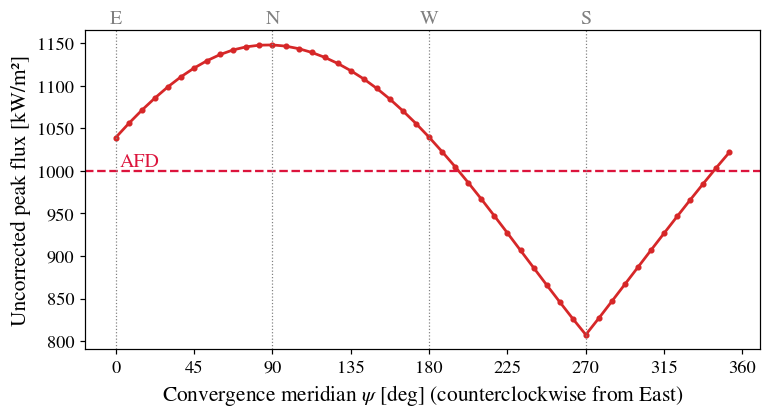

In [6]:
c = Case(psi_deg=RUN['psi_headline'])
psis = np.arange(0.0, 360.0, 7.5); peaks = []
for p in psis:
    dxm, dym, _ = c.displacement_field(p)
    peaks.append(c.flux_map(c.x0_t + dxm, c.y0_t + dym).max())
peaks = np.array(peaks)
rng = np.random.default_rng(7)
rand_peaks = [c.flux_map(c.x0_t + np.cos(a), c.y0_t + np.sin(a)).max()
              for a in (rng.uniform(0, 2*np.pi, c.K) for _ in range(5))]
R['meridian'] = dict(psi=psis.tolist(), peak=peaks.tolist(), worst_psi=float(psis[np.argmax(peaks)]),
                     worst_peak=float(peaks.max()), east_peak=float(peaks[0]), north_peak=float(peaks[12]),
                     south_peak=float(peaks[36]), random_direction_peaks=[float(v) for v in rand_peaks])
print('peak at East / North / South / worst:', R['meridian']['east_peak'], R['meridian']['north_peak'],
      R['meridian']['south_peak'], R['meridian']['worst_peak'], 'at psi =', R['meridian']['worst_psi'])
print('random directions:', np.round(rand_peaks, 1))

fig, ax = plt.subplots(figsize=(7.2, 4.0))
ax.plot(psis, peaks, 'o-', ms=3, color='C3', lw=1.8)
ax.axhline(1000, color='crimson', ls='--'); ax.text(2, 1006, 'AFD', color='crimson')
for p, lab in [(0, 'E'), (90, 'N'), (180, 'W'), (270, 'S')]:
    ax.axvline(p, color='grey', ls=':', lw=0.8)
    ax.text(p, 1.01, lab, color='grey', ha='center', va='bottom', transform=ax.get_xaxis_transform())
ax.set_xticks(np.arange(0, 361, 45))
ax.set_xlabel(r'Convergence meridian $\psi$ [deg] (counterclockwise from East)')
ax.set_ylabel('Uncorrected peak flux [kW/m²]')
fig.tight_layout(); savefig(fig, 'fig_meridian_R1.png'); plt.show()

### 5.0 Heliostat field

The field reconstruction, which does not depend on the misalignment. The nominal flux under the
aiming-factor strategy is panel (a) of the comparison figure in Section 5.2.

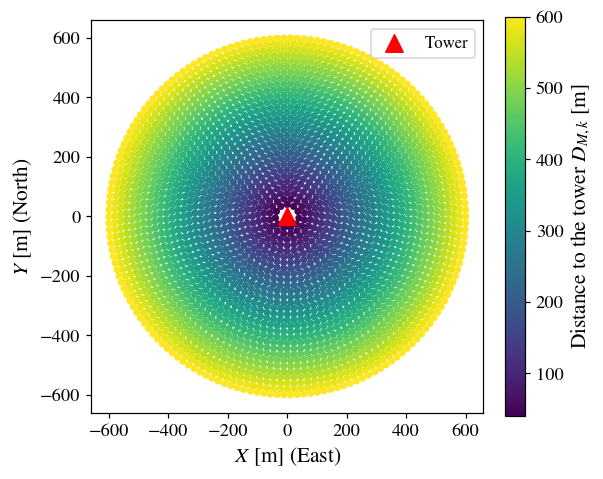

In [7]:
fig, ax = plt.subplots(figsize=(5.6, 5))
sc = ax.scatter(c.X_H, c.Y_H, s=14, c=c.D_M, cmap='viridis')
ax.scatter(0, 0, marker='^', s=130, c='red', label='Tower')
plt.colorbar(sc, ax=ax, label=r'Distance to the tower $D_{M,k}$ [m]', fraction=0.046)
ax.set_aspect('equal'); ax.set_xlabel(r'$X$ [m] (East)'); ax.set_ylabel(r'$Y$ [m] (North)'); ax.legend()
fig.tight_layout(); savefig(fig, 'fig_field_R1.png'); plt.show()

In [8]:
c.set_misalignment(RUN['psi_headline'])
F_ref = uniform_ref(c)
fd = [c.fd_check(k) for k in (10, c.K//2, c.K - 5)]
R['case'] = dict(
    f_aim=c.f_aim, D=[float(c.D.min()), float(c.D.max())], beta_deg=[float(np.degrees(c.beta).min()), float(np.degrees(c.beta).max())],
    sigma_HF=[float(c.sigma_HF.min()), float(c.sigma_HF.max())], sigma_ast_mrad=[float(1e3*c.sigma_ast.min()), float(1e3*c.sigma_ast.max())],
    cos_w_rec=[float(c.cos_w_rec.min()), float(c.cos_w_rec.max())], P_H=[float(c.P_H.min()), float(c.P_H.max())],
    f_at=[float(c.f_at.min()), float(c.f_at.max())], P_field_MW=float(c.P_H.sum()/1e3), F_ref_level=float(F_ref[0]),
    misalignment_beam_mrad=angles_mrad(c, 1.0), fd_check=fd,
    nominal=c.metrics(c.F_nominal), perturbed=c.metrics(c.F_perturbed))
print('nominal  ', R['case']['nominal']); print('perturbed', R['case']['perturbed'])
print('finite-difference check (dx rel. err., dx sign %, dy rel. err., dy sign %):', [tuple(np.round(f, 5)) for f in fd])

nominal   {'peak': 949.9999999993638, 'cv': 0.3058502409293972, 'eta_int': 90.11624150069545, 'P_int_MW': 181.59586560622796, 'mean': 647.6611687682393, 'max_ratio_to_afd': 0.9499999999993638}
perturbed {'peak': 1147.8964087954303, 'cv': 0.40480154901812954, 'eta_int': 89.05155049113841, 'P_int_MW': 179.45037571157687, 'mean': 640.0092847998935, 'max_ratio_to_afd': 1.1478964087954302}
finite-difference check (dx rel. err., dx sign %, dy rel. err., dy sign %): [(np.float64(0.00185), np.float64(100.0), np.float64(0.00163), np.float64(100.0)), (np.float64(0.03434), np.float64(100.0), np.float64(0.00797), np.float64(100.0)), (np.float64(0.00152), np.float64(100.0), np.float64(0.00133), np.float64(100.0))]


### 5.1 Convex QP, one re-linearization step, and the equal-budget baselines

In [9]:
qp = c.solve_qp(c.x0_mis, c.y0_mis, F_ref)
R['qp'] = qp_summary(c, qp); R['qp']['timing'] = qp['timing']
print('QP', {k: R['qp'][k] for k in ('status', 'time', 'peak', 'cv', 'eta_int', 'lin_gap', 'n_cap', 'aim_y_max')})
budget = qp['time']

t0 = time.time(); grp120, G120 = c.make_groups(120, seed=1)
tensor120 = c.build_group_contrib(grp120, G120, 5); t_tensor = time.time() - t0
contrib, cand, n_cand, gxc, gyc = tensor120
R['baseline_setup'] = dict(G=G120, n_cand=n_cand, tensor_MB=contrib.nbytes/1e6, t_tensor=t_tensor, budget=budget)
runs = {'ACO': [], 'GA': []}; best_maps = {}
for s in RUN['seeds']:
    for name in ('ACO', 'GA'):
        t1 = time.time()
        if name == 'ACO':
            best, traj, gens = aco(c, contrib, budget, F_ref, c.F_max_scalar, seed=s, t_offset=t_tensor)
        else:
            best, traj, gens = ga(c, contrib, gxc, gyc, budget, F_ref, c.F_max_scalar, seed=s, t_offset=t_tensor)
        F = evaluate_assignment(c, cand, grp120, best)
        m = c.metrics(F)
        m.update(seed=s, generations=gens, search_time=time.time() - t1, time=time.time() - t1 + t_tensor,
                 t_feasible=next((t for t, pk, cv in traj if pk <= c.F_max_scalar), None), traj=traj)
        runs[name].append(m); best_maps[(name, s)] = F
        print(f"{name} seed {s}: generations {gens}, peak {m['peak']:.1f}, CV {m['cv']:.4f}, eta {m['eta_int']:.2f} %")
R['baselines'] = runs

scp = c.scp_step(qp, F_ref)
R['scp'] = qp_summary(c, scp)
print('SCP', {k: R['scp'][k] for k in ('peak', 'cv', 'eta_int', 'lin_gap', 'time')})
save_results()

QP {'status': 'Solved', 'time': 88.14832186698914, 'peak': 767.0286829601208, 'cv': 0.1827410489024407, 'eta_int': 83.78289130633497, 'lin_gap': 0.05727222157314843, 'n_cap': 1160, 'aim_y_max': 5.249987691388901}


ACO seed 1: generations 688, peak 996.4, CV 0.3624, eta 88.09 %


GA seed 1: generations 53, peak 963.1, CV 0.3312, eta 87.10 %


ACO seed 2: generations 672, peak 999.9, CV 0.3567, eta 87.92 %


GA seed 2: generations 55, peak 976.3, CV 0.3391, eta 87.99 %


...

ACO seed 4: generations 681, peak 997.0, CV 0.3571, eta 88.01 %


GA seed 4: generations 53, peak 981.8, CV 0.3397, eta 87.27 %


ACO seed 5: generations 641, peak 996.4, CV 0.3570, eta 88.15 %


GA seed 5: generations 52, peak 965.0, CV 0.3374, eta 87.70 %


SCP {'peak': 767.1814696433481, 'cv': 0.18869060062757442, 'eta_int': 84.49501431195505, 'lin_gap': 0.03950107328006129, 'time': 28.882476329803467}


### 5.2 Performance table and figures

method                                 peak       CV  eta_int   P_int    time
Nominal (aligned)                     950.0   0.3059    90.12   181.6     0.0
No correction                        1147.9   0.4048    89.05   179.5     0.0
Convex QP (ours)                      767.0   0.1827    83.78   168.8    88.1
Convex QP + one re-linearization      767.2   0.1887    84.50   170.3   117.0
ACO (5 seeds, mean +- sd)          996.4+-2.7  0.3577+-0.0027  88.06+-0.09
GA (5 seeds, mean +- sd)           971.5+-7.8  0.3363+-0.0036  87.55+-0.36


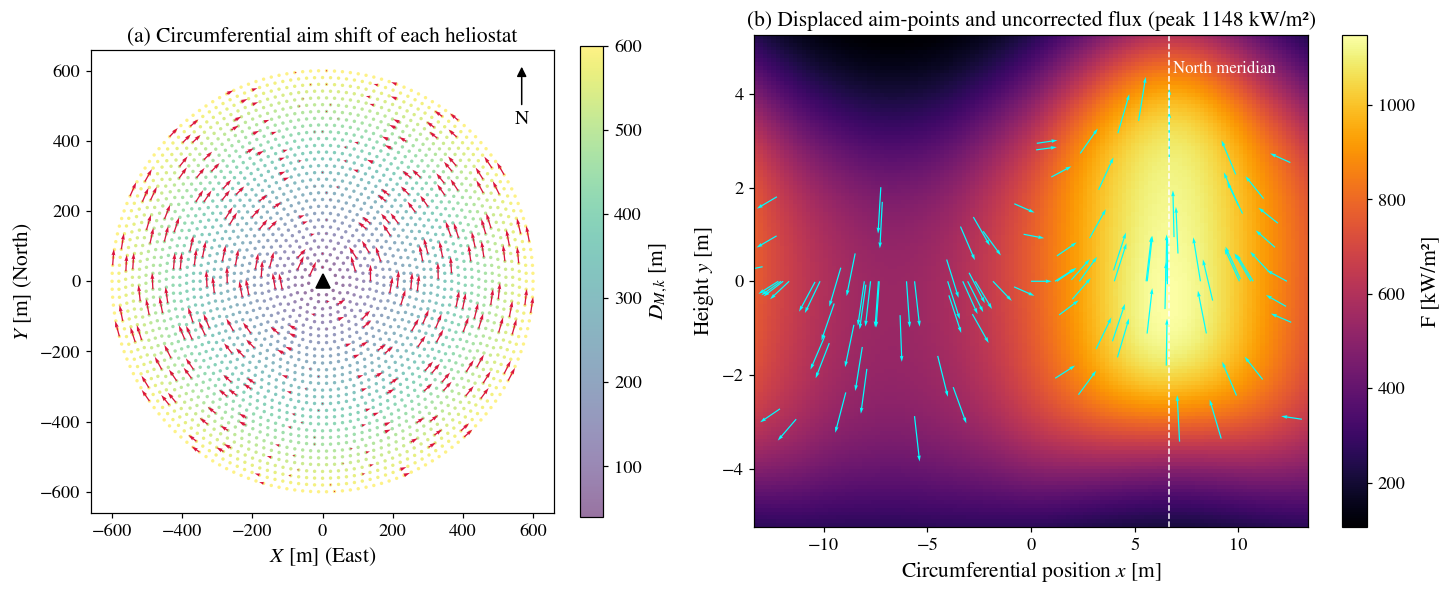

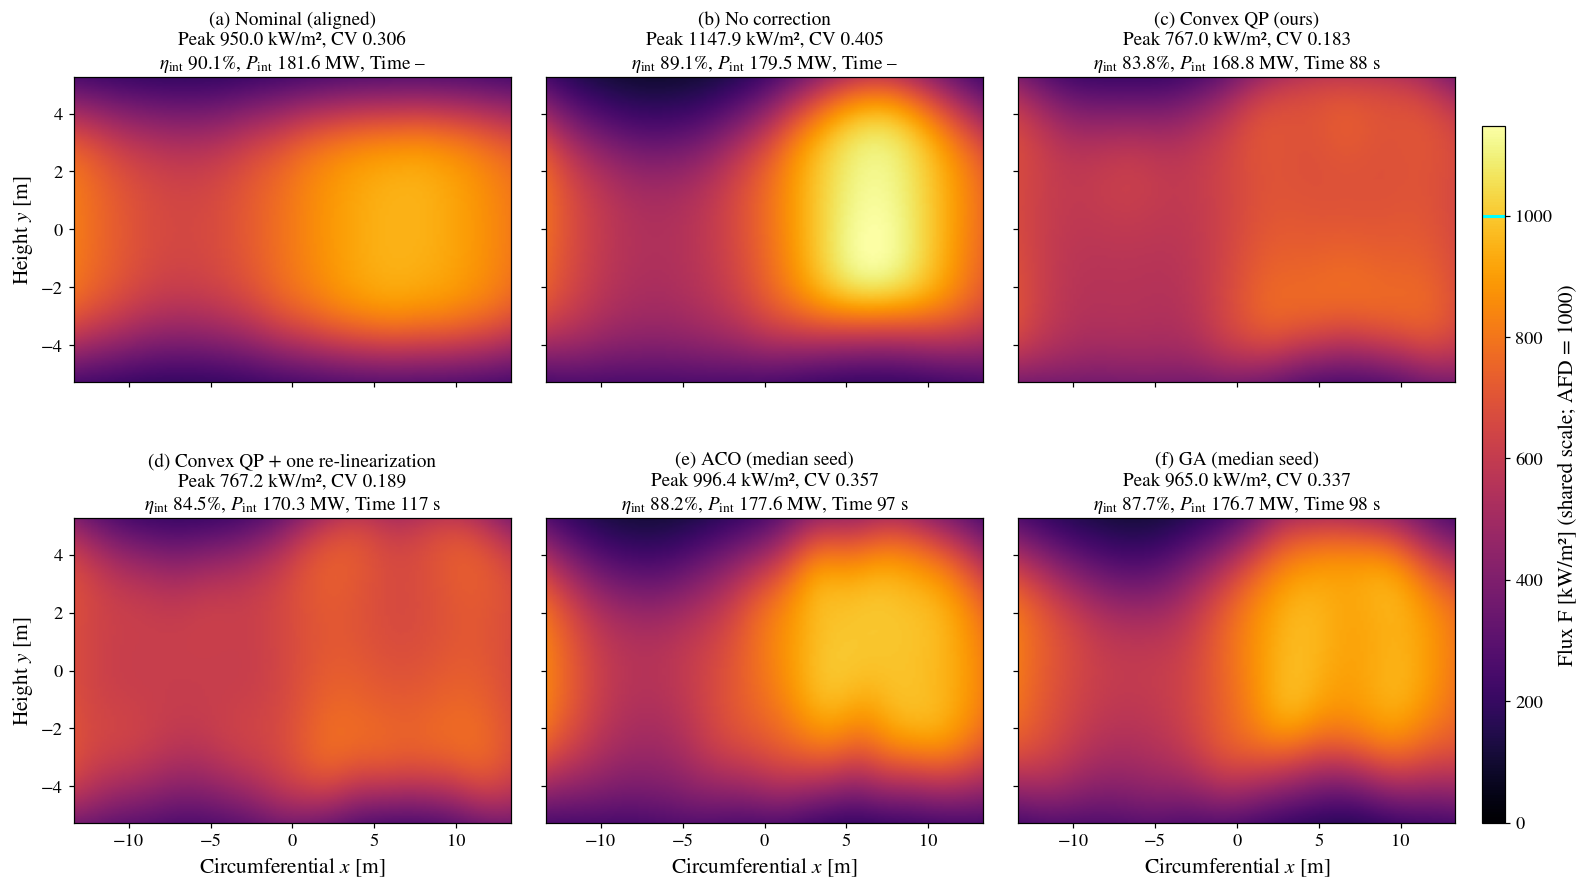

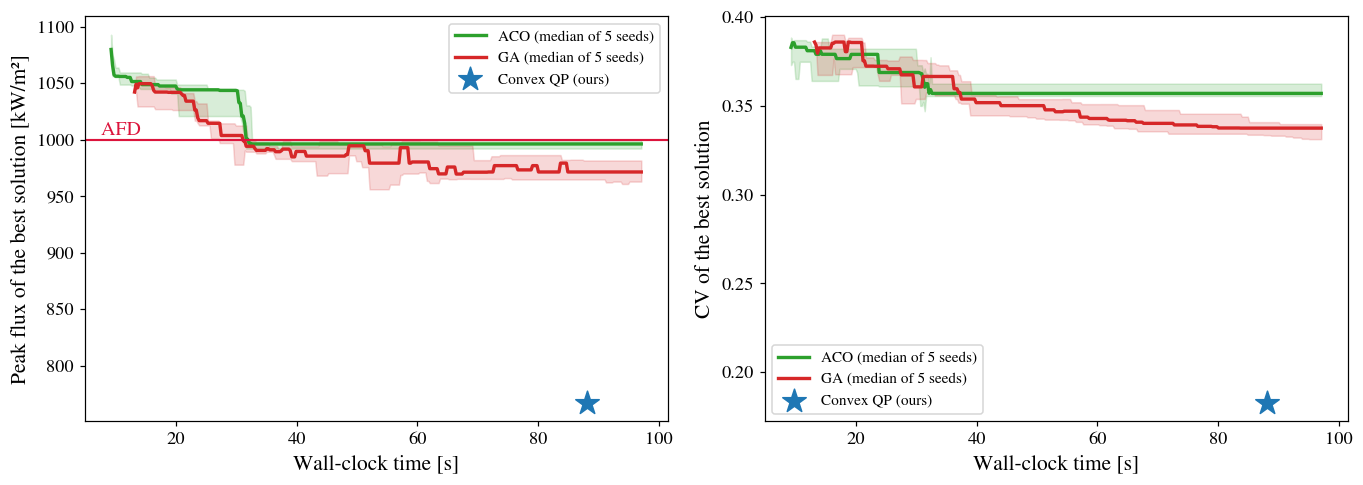

In [10]:
def agg(name, key):
    v = np.array([r[key] for r in R['baselines'][name]]); return v.mean(), v.std(ddof=1), v.min(), v.max()

rows = [('Nominal (aligned)', R['case']['nominal'], None), ('No correction', R['case']['perturbed'], None),
        ('Convex QP (ours)', R['qp'], R['qp']['time']), ('Convex QP + one re-linearization', R['scp'], R['qp']['time'] + R['scp']['time'])]
print(f"{'method':<34}{'peak':>9}{'CV':>9}{'eta_int':>9}{'P_int':>8}{'time':>8}")
for name, m, t in rows:
    print(f"{name:<34}{m['peak']:>9.1f}{m['cv']:>9.4f}{m['eta_int']:>9.2f}{m['P_int_MW']:>8.1f}{(t or 0):>8.1f}")
for name in ('ACO', 'GA'):
    pk, cv, eta = agg(name, 'peak'), agg(name, 'cv'), agg(name, 'eta_int')
    print(f"{name + ' (5 seeds, mean +- sd)':<34}{pk[0]:>6.1f}+-{pk[1]:<4.1f}{cv[0]:>7.4f}+-{cv[1]:.4f}{eta[0]:>7.2f}+-{eta[1]:.2f}")
    R[f'{name}_summary'] = dict(peak=pk, cv=cv, eta_int=eta, time=agg(name, 'time'), generations=agg(name, 'generations'),
                               P_int_MW=agg(name, 'P_int_MW'),
                               t_feasible=[r['t_feasible'] for r in R['baselines'][name]])
save_results()

# misalignment figure (replaces the schematic of the first submission)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13.5, 5.6), gridspec_kw=dict(width_ratios=[1, 1.35]))
sc = a1.scatter(c.X_H, c.Y_H, s=5, c=c.D_M, cmap='viridis', alpha=0.55, linewidths=0)
sel = np.arange(0, c.K, 9); tx, ty = -np.sin(c.theta_h), np.cos(c.theta_h)
a1.quiver(c.X_H[sel], c.Y_H[sel], c.dmech_x[sel]*tx[sel], c.dmech_x[sel]*ty[sel], color='crimson', scale=28, width=0.0028)
a1.plot(0, 0, '^', color='k', ms=9)
a1.annotate('N', xy=(0.93, 0.97), xytext=(0.93, 0.85), xycoords='axes fraction', ha='center', va='center',
            arrowprops=dict(arrowstyle='-|>', color='k'))
a1.set_aspect('equal'); a1.set_xlabel('$X$ [m] (East)'); a1.set_ylabel('$Y$ [m] (North)')
a1.set_title('(a) Circumferential aim shift of each heliostat'); plt.colorbar(sc, ax=a1, fraction=0.046, label='$D_{M,k}$ [m]')
im = a2.imshow(c.F_perturbed.reshape(c.n_v, c.n_h), extent=[-c.C_circ/2, c.C_circ/2, -c.H_rec/2, c.H_rec/2],
               origin='lower', cmap='inferno', aspect='auto')
s2 = np.arange(0, c.K, 25)
a2.quiver(c.x0_t[s2], c.y0_t[s2], c.dmech_x[s2], c.dmech_y[s2], color='cyan', angles='xy', scale_units='xy', scale=1.0, width=0.0022)
a2.axvline(c.R_rec*np.pi/2, color='w', ls='--', lw=1); a2.text(c.R_rec*np.pi/2 + 0.2, c.H_rec/2 - 0.8, 'North meridian', color='w', fontsize=11)
a2.set_xlabel('Circumferential position $x$ [m]'); a2.set_ylabel('Height $y$ [m]')
a2.set_title(f'(b) Displaced aim-points and uncorrected flux (peak {c.F_perturbed.max():.0f} kW/m²)')
plt.colorbar(im, ax=a2, label='F [kW/m²]'); fig.tight_layout(); savefig(fig, 'fig6_misalignment_R1.png'); plt.show()

# comparison maps: the six rows of the performance table (ACO and GA: median-CV seed)
def median_seed(name):
    rs = R['baselines'][name]; return rs[int(np.argsort([r['cv'] for r in rs])[len(rs)//2])]
aco_m, ga_m = median_seed('ACO'), median_seed('GA')
panels = [(c.F_nominal, 'Nominal (aligned)', R['case']['nominal'], None),
          (c.F_perturbed, 'No correction', R['case']['perturbed'], None),
          (qp['F_true'], 'Convex QP (ours)', R['qp'], R['qp']['time']),
          (scp['F_true'], 'Convex QP + one re-linearization', R['scp'], R['qp']['time'] + R['scp']['time']),
          (best_maps[('ACO', aco_m['seed'])], 'ACO (median seed)', aco_m, aco_m['time']),
          (best_maps[('GA', ga_m['seed'])], 'GA (median seed)', ga_m, ga_m['time'])]
vmax = max(F.max() for F, *_ in panels)
fig, axs = plt.subplots(2, 3, figsize=(16.0, 9.2), sharex=True, sharey=True)
for k, (ax, (F, name, m, t)) in enumerate(zip(axs.ravel(), panels)):
    im = ax.imshow(F.reshape(c.n_v, c.n_h), extent=[-c.C_circ/2, c.C_circ/2, -c.H_rec/2, c.H_rec/2],
                   origin='lower', cmap='inferno', vmin=0, vmax=vmax, aspect='auto')
    title = [f"({'abcdef'[k]}) {name}", f"Peak = {m['peak']:.1f} kW/m², CV = {m['cv']:.3f}",
             r'$\eta_{\mathrm{int}}$' + f" = {m['eta_int']:.1f}%, " + r'$P_{\mathrm{int}}$' + f" = {m['P_int_MW']:.1f} MW",
             'Computational time = ' + ('–' if t is None else f'{t:.0f} s')]
    for i, line in enumerate(title[::-1]):          # one line at a time: even spacing, bold panel heading
        ax.annotate(line, xy=(0.5, 1), xycoords='axes fraction', xytext=(0, 5 + 13.2*i), textcoords='offset points',
                    ha='center', va='baseline', fontsize=12.5, fontweight='bold' if i == 3 else 'normal')
for ax in axs[1]: ax.set_xlabel('Circumferential $x$ [m]')
for ax in axs[:, 0]: ax.set_ylabel('Height $y$ [m]')
fig.subplots_adjust(right=0.91, wspace=0.08, hspace=0.55)
cb = fig.colorbar(im, cax=fig.add_axes([0.925, 0.11, 0.013, 0.72]), label='Flux F [kW/m²] (shared scale; AFD = 1000)')
cb.ax.axhline(1000, color='cyan', lw=2); savefig(fig, 'fig10_comparison_R1.png'); plt.show()

# anytime performance (median and range over seeds; no value exists before a seed's first logged solution)
import warnings
warnings.filterwarnings('ignore', message='All-NaN slice encountered')
fig, (ap, ac) = plt.subplots(1, 2, figsize=(12.6, 4.6))
tgrid = np.linspace(0, budget + t_tensor, 400)
for name, col in [('ACO', 'C2'), ('GA', 'C3')]:
    PK, CV = [], []
    for r in R['baselines'][name]:
        tr = np.array(r['traj']); idx = np.searchsorted(tr[:, 0], tgrid, side='right') - 1
        PK.append(np.where(idx >= 0, tr[np.maximum(idx, 0), 1], np.nan)); CV.append(np.where(idx >= 0, tr[np.maximum(idx, 0), 2], np.nan))
    for ax, Y in ((ap, np.array(PK)), (ac, np.array(CV))):
        ax.plot(tgrid, np.nanmedian(Y, 0), color=col, lw=2.2, label=f'{name} (median of 5 seeds)')
        ax.fill_between(tgrid, np.nanmin(Y, 0), np.nanmax(Y, 0), color=col, alpha=0.18)
ap.scatter([R['qp']['time']], [R['qp']['peak']], marker='*', s=260, color='C0', zorder=5, label='Convex QP (ours)')
ac.scatter([R['qp']['time']], [R['qp']['cv']], marker='*', s=260, color='C0', zorder=5, label='Convex QP (ours)')
ap.axhline(1000, color='crimson', lw=1.4); ap.text(0.02, 1004, ' AFD', color='crimson', transform=ap.get_yaxis_transform())
for ax in (ap, ac): ax.set_xlabel('Computational time [s]'); ax.legend(fontsize=10)
ap.set_ylabel('Peak flux of the best solution [kW/m²]'); ac.set_ylabel('CV of the best solution')
fig.tight_layout(); savefig(fig, 'fig13_anytime_R1.png'); plt.show()

## 6. Validity of the linearization (Reviewer 1, comment 1)

(a) Correction size $s_k=\|\boldsymbol\delta^*_k\|/\sigma_{HF,k}$ at the optimum. (b) Relative $\ell_2$ error between the
linearized and the exact flux when a fraction $t$ of the optimal correction is applied, compared with the single-beam
closed form $\epsilon_{\ell_2}(s)=\sqrt{1+(1+s^2/2)(1-2e^{-s^2/4})}$ (Eq. 12) for the narrowest and widest beams at their optimal corrections;
the closed form is checked here numerically. The sweep of the correction bound is computed for reference only.

In [ ]:
x = np.linspace(-12, 12, 2401); X, Y = np.meshgrid(x, x); single = []
for s in [0.25, 0.5, 0.84, 1.0, 1.19]:
    true = np.exp(-((X - s)**2 + Y**2)/2); lin = np.exp(-(X**2 + Y**2)/2)*(1 + s*X)
    closed = np.sqrt(1 + (1 + s**2/2)*(1 - 2*np.exp(-s**2/4)))
    single.append(dict(s=s, closed=float(closed), grid=float(np.linalg.norm(lin - true)/np.linalg.norm(true)),
                       centre=float(1 - np.exp(-s**2/2)), max_pointwise=float(np.max(np.abs(lin - true)))))
R['lin_single_beam'] = single
for row in single: print(row)

dx, dy = qp['dx'], qp['dy']; sig = c.sigma_HF; dmax = c.C['delta_max']
s_eucl = np.hypot(dx, dy)/sig; s_axis = np.maximum(np.abs(dx), np.abs(dy))/sig
lb, ub = c.bounds(c.y0_mis)
tol = 1e-3*dmax                                   # same relative tolerance for both axes (solver tol 1e-4)
at_x = np.abs(dx) >= dmax - tol; at_y = (dy <= lb[c.K:] + tol) | (dy >= ub[c.K:] - tol)
S_mis = c.build_sensitivity(c.x0_mis, c.y0_mis); z = np.concatenate([dx, dy]); gap_t = []
for t in [0.1, 0.25, 0.5, 0.75, 1.0, 1.25, 1.5, 2.0]:
    Fl = c.lin_flux(S_mis, t*z); Ft = c.flux_map(c.x0_mis + t*dx, c.y0_mis + t*dy)
    gap_t.append(dict(t=t, gap_l2=float(np.linalg.norm(Fl - Ft)/np.linalg.norm(Ft)), peak_lin=float(Fl.max()),
                      peak_true=float(Ft.max()), max_abs_err_kW=float(np.max(np.abs(Fl - Ft)))))
sweep = []
for dm in [0.25, 0.5, 0.75, 1.0, 1.5, 2.0]:
    r = c.solve_qp(c.x0_mis, c.y0_mis, F_ref, delta_max=dm)
    srow = qp_summary(c, r); srow['delta_max'] = dm; sweep.append(srow)
    print('delta_max', dm, {k: srow.get(k) for k in ('status', 'peak', 'cv', 'eta_int', 'lin_gap', 'cap_exceed')})
R['lin'] = dict(bound_over_sigma=[float(dmax/sig.max()), float(dmax/sig.min())],
                s_eucl=dict(median=float(np.median(s_eucl)), p90=float(np.percentile(s_eucl, 90)), max=float(s_eucl.max())),
                s_axis=dict(median=float(np.median(s_axis)), p90=float(np.percentile(s_axis, 90)), max=float(s_axis.max())),
                frac_at_x_bound=float(at_x.mean()), frac_at_y_bound=float(at_y.mean()), frac_any_bound=float((at_x | at_y).mean()),
                frac_at_both_bounds=float((at_x & at_y).mean()),
                gap_vs_t=gap_t, delta_sweep=sweep)
save_results()
print({k: R['lin'][k] for k in ('s_eucl', 'frac_any_bound')})

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11.5, 4.1))
a1.hist(s_eucl, bins=40, color='C0', alpha=0.8)
med = np.median(s_eucl); a1.axvline(med, color='k', ls='--', lw=1.2)
a1.text(med, 0.97, f'  median {med:.2f}', transform=a1.get_xaxis_transform(), va='top', ha='left')
a1.set_xlabel(r'$s_k=\|\boldsymbol{\delta}^*_k\|/\sigma_{HF,k}$ [–]'); a1.set_ylabel('Number of heliostats')
a1.set_title('(a) Correction size at the optimum')
eps = lambda s: np.sqrt(1 + (1 + s**2/2)*(1 - 2*np.exp(-s**2/4)))      # single-beam closed form, Eq. (12)
tf = np.linspace(0, 2, 201); s_in, s_out = s_eucl[np.argmin(sig)], s_eucl[np.argmax(sig)]   # narrowest / widest beam at the optimum
a2.plot(tf, 100*eps(s_in*tf), '--', color='0.45', lw=1.6, label=f'Narrowest beam, Eq. (12) ($s_k={s_in:.2f}$ at the optimum)')
a2.plot(tf, 100*eps(s_out*tf), ':', color='0.45', lw=2.0, label=f'Widest beam, Eq. (12) ($s_k={s_out:.2f}$ at the optimum)')
a2.plot([g['t'] for g in gap_t], [100*g['gap_l2'] for g in gap_t], 'o-', color='C3', lw=2, label='Whole field (linearized vs. exact flux)')
a2.axvline(1, ymax=0.68, color='k', ls=':', lw=1); a2.text(1.03, 0.66, 'optimum', transform=a2.get_xaxis_transform(), va='top')
a2.set_xlim(0, 2); a2.set_ylim(0, 60)
a2.set_xlabel('Applied correction / optimal correction [–]'); a2.set_ylabel(r'Relative $\ell_2$ error [%]')
a2.set_title('(b) Linearization error versus correction size'); a2.legend(loc='upper left', frameon=True, framealpha=1, edgecolor='none')
fig.tight_layout(); savefig(fig, 'fig_linearization_R1.png'); plt.show()

## 7. Allowable-flux-density profile (Reviewer 1, comment 2)

The AFD profile of Sánchez-González et al. (2017) is mapped onto the receiver grid and scaled by a single
factor $\kappa$ so that the nominal aiming keeps the same 5 % margin as in the scalar case (our plant model
delivers more power than theirs, hence a higher salt mass flow and a higher AFD); it is capped at the scalar
1000 kW/m². The QP is then solved (i) with the uniform reference and this per-pixel limit and (ii) with an
AFD-shaped reference, $F_{ref,ij}\propto F_{\max,ij}$ (equal relative margin everywhere).

uniform_ref {'status': 'Solved', 'feasible': True, 'time': 95.73250246047974, 'lin_gap': 0.05727222157314843, 'n_cap': 1160, 'step_sigma_min': 0.8409152135849413, 'cap_exceed': 0.0, 'aim_y_max': 5.249987691388901, 'peak': 767.0286829601208, 'cv': 0.1827410489024407, 'eta_int': 83.78289130633497, 'P_int_MW': 168.833346979401, 'mean': 602.1436802357598, 'max_ratio_to_afd': 0.8964488883596458, 'rel_dev_to_ref': 0.18386025875394732, 'min_margin': 0.10355111164035424}


afd_ref {'status': 'Solved', 'feasible': True, 'time': 103.79663419723511, 'lin_gap': 0.05722266056153859, 'n_cap': 1160, 'step_sigma_min': 0.8409137601726799, 'cap_exceed': 0.0, 'aim_y_max': 5.249976853449205, 'peak': 774.6651484394883, 'cv': 0.19658532277569918, 'eta_int': 83.83243313834913, 'P_int_MW': 168.93318016949536, 'mean': 602.4997350410965, 'max_ratio_to_afd': 0.8004479216469956, 'rel_dev_to_ref': 0.16470901509235092, 'min_margin': 0.19955207835300437}


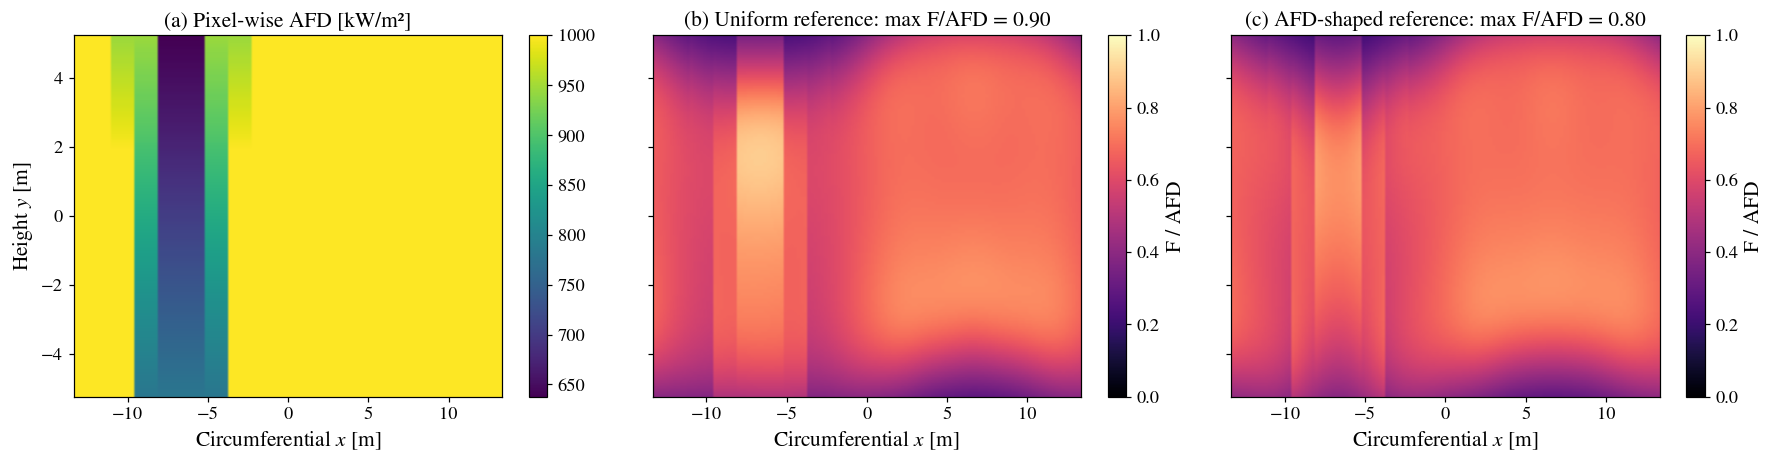

In [12]:
shape = afd_shape(c)
kappa = float(np.max(c.F_nominal/(c.C['nominal_peak_target']*shape)))
Fmax_px = np.minimum(c.F_max_scalar, kappa*shape)
F_afd_ref = Fmax_px*(F_ref.sum()/Fmax_px.sum())
R['afd'] = dict(kappa=kappa, Fmax_px_range=[float(Fmax_px.min()), float(Fmax_px.max())],
                nominal_max_ratio=float(np.max(c.F_nominal/Fmax_px)), perturbed_max_ratio=float(np.max(c.F_perturbed/Fmax_px)),
                perturbed_violation_area=float(np.mean(c.F_perturbed > Fmax_px)))
afd_maps = {}
for name, Fr in [('uniform_ref', F_ref), ('afd_ref', F_afd_ref)]:
    r = c.solve_qp(c.x0_mis, c.y0_mis, Fr, Fmax_px)
    srow = qp_summary(c, r, Fmax_px)
    if r['dx'] is not None:
        srow['rel_dev_to_ref'] = float(np.linalg.norm(r['F_true'] - Fr)/np.linalg.norm(Fr))
        srow['min_margin'] = float(np.min(1 - r['F_true']/Fmax_px)); afd_maps[name] = r['F_true']
    R['afd'][name] = srow; print(name, srow)
R['afd']['uncorrected_rel_dev_to_afd_ref'] = float(np.linalg.norm(c.F_perturbed - F_afd_ref)/np.linalg.norm(F_afd_ref))
save_results()

fig, axs = plt.subplots(1, 3, figsize=(16.5, 4.4), sharey=True)
ext = [-c.C_circ/2, c.C_circ/2, -c.H_rec/2, c.H_rec/2]
im0 = axs[0].imshow(Fmax_px.reshape(c.n_v, c.n_h), extent=ext, origin='lower', cmap='viridis', aspect='auto')
axs[0].set_title('(a) Pixel-wise AFD [kW/m²]'); plt.colorbar(im0, ax=axs[0])
for ax, key, t in [(axs[1], 'uniform_ref', '(b) Uniform reference'), (axs[2], 'afd_ref', '(c) AFD-shaped reference')]:
    if key not in afd_maps: continue
    Q = (afd_maps[key]/Fmax_px).reshape(c.n_v, c.n_h)
    im = ax.imshow(Q, extent=ext, origin='lower', cmap='magma', vmin=0, vmax=1, aspect='auto')
    ax.set_title(t + f': max F/AFD = {Q.max():.2f}'); plt.colorbar(im, ax=ax, label='F / AFD')
for ax in axs: ax.set_xlabel('Circumferential $x$ [m]')
axs[0].set_ylabel('Height $y$ [m]'); fig.tight_layout(); savefig(fig, 'fig_afd_R1.png'); plt.show()

## 8. Uniformity-interception trade-off (Reviewer 1, comment 3)

Reference blend $F_{ref}(\lambda)=(1-\lambda)F_{nom}+\lambda F_{uni}$, a spillage margin $m\sigma_{HF,k}$ on the
vertical aim bound, a lower uniform level, and the operator's alternative: defocusing the heliostats that
feed the hot spot until the peak meets the limit.

{'lam': 0.0, 'margin_sigma': 0.0, 'level': 1.0, 'peak': 937.2038589580395, 'cv': 0.29133122713416354, 'eta_int': 88.4723271830267}
{'lam': 0.25, 'margin_sigma': 0.0, 'level': 1.0, 'peak': 897.5984921835918, 'cv': 0.24765809905562103, 'eta_int': 87.10523661755512}
{'lam': 0.5, 'margin_sigma': 0.0, 'level': 1.0, 'peak': 841.3070552057884, 'cv': 0.21478927044413165, 'eta_int': 85.7616857373906}
{'lam': 0.75, 'margin_sigma': 0.0, 'level': 1.0, 'peak': 779.7472167805691, 'cv': 0.1932640319753484, 'eta_int': 84.63228923770724}
{'lam': 1.0, 'margin_sigma': 0.0, 'level': 1.0, 'peak': 767.0286829601208, 'cv': 0.1827410489024407, 'eta_int': 83.78289130633497}
{'lam': 1.0, 'margin_sigma': 0.5, 'level': 1.0, 'peak': 769.3843309424327, 'cv': 0.18472473709351944, 'eta_int': 84.17791774750285}
{'lam': 1.0, 'margin_sigma': 1.0, 'level': 1.0, 'peak': 806.5487209476079, 'cv': 0.20563567974181518, 'eta_int': 85.9632292009954}
{'lam': 1.0, 'margin_sigma': 0.0, 'level': 0.93, 'peak': 757.9749297277057, 'cv

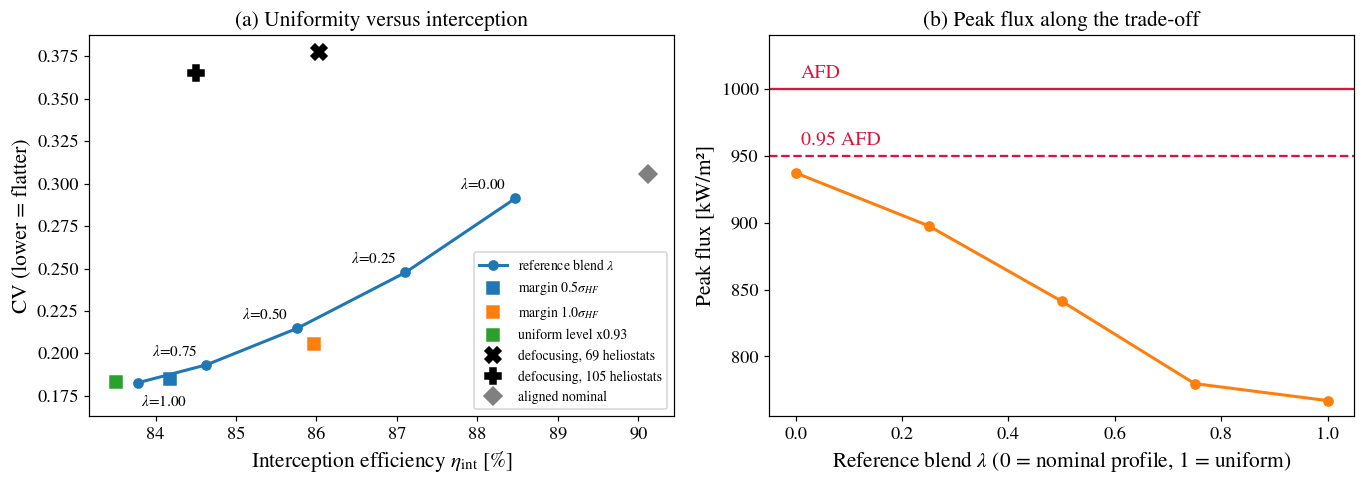

In [13]:
trade = []
for lam in [0.0, 0.25, 0.5, 0.75, 1.0]:
    if lam == 1.0:
        srow = dict(R['qp'])
    else:
        srow = qp_summary(c, c.solve_qp(c.x0_mis, c.y0_mis, (1 - lam)*c.F_nominal + lam*F_ref))
    srow.update(lam=lam, margin_sigma=0.0, level=1.0); trade.append(srow)
for m in [0.5, 1.0]:
    srow = qp_summary(c, c.solve_qp(c.x0_mis, c.y0_mis, F_ref, aim_margin_sigma=m)); srow.update(lam=1.0, margin_sigma=m, level=1.0); trade.append(srow)
srow = qp_summary(c, c.solve_qp(c.x0_mis, c.y0_mis, 0.93*F_ref)); srow.update(lam=1.0, margin_sigma=0.0, level=0.93); trade.append(srow)
for row in trade: print({k: row.get(k) for k in ('lam', 'margin_sigma', 'level', 'peak', 'cv', 'eta_int')})
R['tradeoff'] = dict(runs=trade, MW_per_point=float(c.P_H.sum()/1e3/100))
for lim_name, lim in [('afd', c.F_max_scalar), ('margin95', 0.95*c.F_max_scalar)]:
    n_rm, F_def = defocus(c, c.x0_mis, c.y0_mis, lim)
    R['tradeoff'][f'defocus_{lim_name}'] = dict(n_removed=n_rm, **c.metrics(F_def)); print('defocus to', lim, ':', n_rm, c.metrics(F_def))
save_results()

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12.6, 4.6))
lam_rows = [r for r in trade if r['margin_sigma'] == 0 and r['level'] == 1.0 and r.get('feasible')]
a1.plot([r['eta_int'] for r in lam_rows], [r['cv'] for r in lam_rows], 'o-', color='C0', lw=2, label=r'reference blend $\lambda$')
for r in lam_rows:
    below = r['lam'] == 1.0
    a1.annotate(f"$\\lambda$={r['lam']:.2f}", (r['eta_int'], r['cv']), textcoords='offset points',
                xytext=(2, -15) if below else (-6, 6), ha='left' if below else 'right', fontsize=10)
for r in [r for r in trade if (r['margin_sigma'] > 0 or r['level'] != 1.0) and r.get('feasible')]:
    a1.plot(r['eta_int'], r['cv'], 's', ms=8, label=(f"margin {r['margin_sigma']}" + r'$\sigma_{HF}$') if r['margin_sigma'] > 0 else f"uniform level x{r['level']}")
for key, mk in [('defocus_afd', 'X'), ('defocus_margin95', 'P')]:
    d = R['tradeoff'][key]; a1.plot(d['eta_int'], d['cv'], mk, ms=11, color='k', label=f"defocusing, {d['n_removed']} heliostats")
a1.plot(R['case']['nominal']['eta_int'], R['case']['nominal']['cv'], 'D', color='grey', ms=8, label='aligned nominal')
a1.set_ylim(bottom=0.163)
a1.set_xlabel(r'Interception efficiency $\eta_{\mathrm{int}}$ [%]'); a1.set_ylabel('CV (lower = flatter)'); a1.legend(fontsize=9)
a1.set_title('(a) Uniformity versus interception')
a2.plot([r['lam'] for r in lam_rows], [r['peak'] for r in lam_rows], 'o-', color='C1', lw=2)
a2.axhline(1000, color='crimson'); a2.axhline(950, color='crimson', ls='--'); a2.set_ylim(top=1040)
a2.text(0.01, 1008, 'AFD', color='crimson'); a2.text(0.01, 958, '0.95 AFD', color='crimson')
a2.set_xlabel(r'Reference blend $\lambda$ (0 = nominal profile, 1 = uniform)'); a2.set_ylabel('Peak flux [kW/m²]')
a2.set_title('(b) Peak flux along the trade-off'); fig.tight_layout(); savefig(fig, 'fig_tradeoff_R1.png'); plt.show()

## 9. Operating conditions over the day and the year (Reviewer 1, comments 5 and 8)

Five sun positions at the Gemasolar latitude, with the DNI fixed at 0.95 kW/m² so that only the geometry
changes; the clear-sky (Hottel) DNI of each condition is recorded for comparison. The nominal aiming is
re-tuned at each condition, as an operator would, and the same structural drift is applied. For each
condition: the QP, the Phase-1 pointing budget, and the equinox-noon correction kept unchanged.

equinox_noon elev 52.0, f_aim 1.53, uncorrected 1148, QP 767/0.183/83.78, budget 0.75 m, noon correction kept 767


summer_noon elev 75.9, f_aim 1.71, uncorrected 1147, QP 777/0.185/86.05, budget 0.69 m, noon correction kept 778


winter_noon elev 29.0, f_aim 1.45, uncorrected 1149, QP 759/0.240/82.80, budget 1.03 m, noon correction kept 777


equinox_0900 elev 33.8, f_aim 1.46, uncorrected 1092, QP 735/0.196/82.98, budget 0.83 m, noon correction kept 827


equinox_1500 elev 33.8, f_aim 1.46, uncorrected 1095, QP 734/0.196/82.97, budget 0.83 m, noon correction kept 826


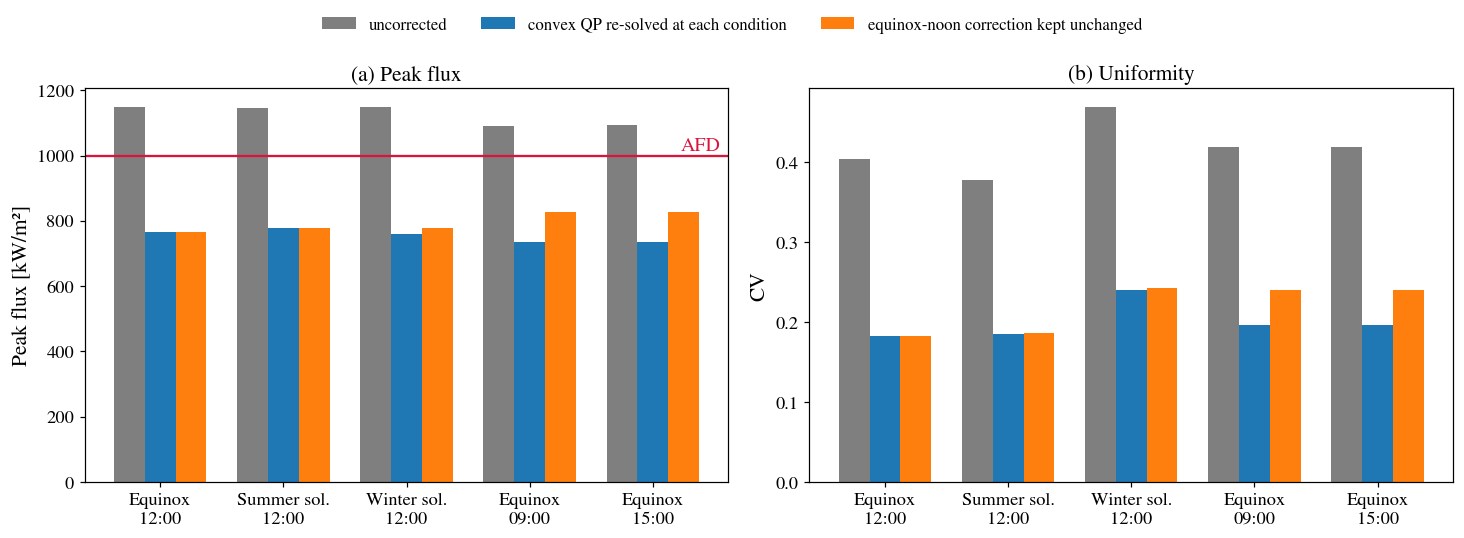

In [14]:
CONDITIONS = [('equinox_noon', 80, 12.0), ('summer_noon', 172, 12.0), ('winter_noon', 355, 12.0),
              ('equinox_0900', 80, 9.0), ('equinox_1500', 80, 15.0)]
dx0, dy0 = qp['dx'], qp['dy']; R['conditions'] = {}
for name, doy, hr in CONDITIONS:
    ck = c if name == 'equinox_noon' else Case(psi_deg=RUN['psi_headline'], doy=doy, solar_hour=hr)
    rec = dict(doy=doy, hour=hr, elevation=float(ck.elevation), sun_azimuth=float((np.degrees(np.arctan2(ck.S[0], ck.S[1])) + 360) % 360),
               f_aim=ck.f_aim, sigma_HF=[float(ck.sigma_HF.min()), float(ck.sigma_HF.max())],
               sigma_ast_mrad=[float(1e3*ck.sigma_ast.min()), float(1e3*ck.sigma_ast.max())],
               P_field_MW=float(ck.P_H.sum()/1e3), bound_over_sigma=[float(1/ck.sigma_HF.max()), float(1/ck.sigma_HF.min())],
               nominal=ck.metrics(ck.F_nominal), perturbed=ck.metrics(ck.F_perturbed), hottel_dni=hottel_dni(doy, ck.elevation))
    if name == 'equinox_noon':
        rk = qp
    else:
        rk = ck.solve_qp(ck.x0_mis, ck.y0_mis, uniform_ref(ck))
    rec['qp'] = qp_summary(ck, rk)
    if rk['dx'] is not None:
        cvd = ck.uniformity(rk['F_true']); ratios = ratio_grid()
        sw = decoupling_sweep(ck, rk['dx'], rk['dy'], ratios)
        rec['decoupling'] = summarise_decoupling(ck, sw, ratios, cvd, pointing_budget(ck, rk['dx'], rk['dy'], cvd, ratios, sw['coherent']['cv_dep'].mean(0)))
        if name == 'equinox_noon':
            sw_headline, ratios_headline = sw, ratios
    ys = np.clip(ck.y0_mis + dy0, -ck.H_rec/2, ck.H_rec/2)
    rec['static_noon_correction'] = ck.metrics(ck.flux_map(ck.x0_mis + dx0, ys))
    R['conditions'][name] = rec
    print(name, f"elev {rec['elevation']:.1f}, f_aim {rec['f_aim']:.2f}, uncorrected {rec['perturbed']['peak']:.0f},",
          f"QP {rec['qp'].get('peak', float('nan')):.0f}/{rec['qp'].get('cv', float('nan')):.3f}/{rec['qp'].get('eta_int', float('nan')):.2f},",
          f"budget {rec.get('decoupling', {}).get('threshold_m', float('nan')):.2f} m, noon correction kept {rec['static_noon_correction']['peak']:.0f}")
save_results()

names = [n for n, _, _ in CONDITIONS]
lab = {'equinox_noon': 'Equinox\n12:00', 'summer_noon': 'Summer sol.\n12:00', 'winter_noon': 'Winter sol.\n12:00',
       'equinox_0900': 'Equinox\n09:00', 'equinox_1500': 'Equinox\n15:00'}
xb = np.arange(len(names)); w = 0.25
series = [('uncorrected', 'perturbed', 'C7'), ('convex QP re-solved at each condition', 'qp', 'C0'),
          ('equinox-noon correction kept unchanged', 'static_noon_correction', 'C1')]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13.5, 4.6))
for i, (label, key, col) in enumerate(series):
    a1.bar(xb + (i - 1)*w, [R['conditions'][n][key].get('peak', np.nan) for n in names], w, color=col, label=label)
    a2.bar(xb + (i - 1)*w, [R['conditions'][n][key].get('cv', np.nan) for n in names], w, color=col)
a1.axhline(1000, color='crimson'); a1.text(len(names) - 0.45, 1015, 'AFD', color='crimson', ha='right')
a1.set_ylabel('Peak flux [kW/m²]'); a1.set_title('(a) Peak flux'); a2.set_ylabel('CV'); a2.set_title('(b) Uniformity')
for ax in (a1, a2): ax.set_xticks(xb); ax.set_xticklabels([lab[n] for n in names])
fig.legend(*a1.get_legend_handles_labels(), loc='upper center', ncol=3, bbox_to_anchor=(0.5, 1.08), frameon=False)
fig.tight_layout(); savefig(fig, 'fig_conditions_R1.png'); plt.show()

## 10. Phase-1/Phase-2 decoupling, refined (Reviewer 1, comment 5)

26 residual levels (including $\varepsilon=\Delta_{mech}$), five random draws per structure, the pointing budget
located by bisection, and the oracle re-optimized at every third level. For each oracle point the number of
aim-points pushed off the receiver by the residual is recorded, since those must be pulled back by the
on-receiver bound.

{'ratio': 0.01, 'status': 'Solved', 'n_pinned': 0, 'n_off_receiver': 0, 'deployed_cv': 0.18273631190625003, 'deployed_peak': 767.0120351764049, 'cv': 0.1827004993694399, 'peak': 766.9829927745657, 'lin_gap': 0.05733657977325531, 'eta_int': 83.79186985649052}


{'ratio': 0.020400469235504898, 'status': 'Solved', 'n_pinned': 0, 'n_off_receiver': 0, 'deployed_cv': 0.18274007758561453, 'deployed_peak': 766.9945382579273, 'cv': 0.18259807035239103, 'peak': 766.8986033337297, 'lin_gap': 0.05740623070658685, 'eta_int': 83.80571582018312}


{'ratio': 0.041617914502878176, 'status': 'Solved', 'n_pinned': 0, 'n_off_receiver': 0, 'deployed_cv': 0.18277523347304872, 'deployed_peak': 767.0298753160013, 'cv': 0.18254853034981408, 'peak': 766.7430322604183, 'lin_gap': 0.0575365166498603, 'eta_int': 83.82371076265427}


{'ratio': 0.08490249844618393, 'status': 'Solved', 'n_pinned': 0, 'n_off_receiver': 0, 'deployed_cv': 0.18296113373958933, 'deployed_peak': 767.0318522195743, 'cv': 0.18245334534478225, 'peak': 766.2495770829048, 'lin_gap': 0.05774171926365696, 'eta_int': 83.86204424842889}


{'ratio': 0.17320508075688776, 'status': 'Solved', 'n_pinned': 0, 'n_off_receiver': 0, 'deployed_cv': 0.18381279912533557, 'deployed_peak': 767.0312074204465, 'cv': 0.18263012926558064, 'peak': 764.6775990140018, 'lin_gap': 0.058194274326472124, 'eta_int': 83.92654308691368}


{'ratio': 0.353346492141403, 'status': 'Solved', 'n_pinned': 0, 'n_off_receiver': 0, 'deployed_cv': 0.1874697618133655, 'deployed_peak': 767.0502195465173, 'cv': 0.18433485373168743, 'peak': 759.0886458452363, 'lin_gap': 0.058804760509847384, 'eta_int': 84.07334115101204}


{'ratio': 0.7208434242404265, 'status': 'Solved', 'n_pinned': 0, 'n_off_receiver': 0, 'deployed_cv': 0.20219986732969647, 'deployed_peak': 767.0457792550071, 'cv': 0.19306840059843378, 'peak': 752.0859016868898, 'lin_gap': 0.060283543233898, 'eta_int': 84.1809727697599}


{'ratio': 1.159491881803038, 'status': 'Solved', 'n_pinned': 0, 'n_off_receiver': 0, 'deployed_cv': 0.22986119995373475, 'deployed_peak': 767.0023217446607, 'cv': 0.21231460122166607, 'peak': 749.5799738673715, 'lin_gap': 0.06237420668884426, 'eta_int': 83.92797276457166}


{'ratio': 2.3654178463540556, 'status': 'Solved', 'n_pinned': 0, 'n_off_receiver': 69, 'deployed_cv': 0.33532694210491165, 'deployed_peak': 767.0462803014686, 'cv': 0.3053559851054595, 'peak': 784.4994783123699, 'lin_gap': 0.06392639798330303, 'eta_int': 81.08516097214519}
{'coh_dep_cv_at_1': 0.21411975140929954, 'coh_unc_cv_at_1': 0.42727997859190064, 'retained_at_1': 0.8716821794112428, 'rand_dep_cv_at_1': 0.18145270933015673, 'coh_dep_cv_at_3': 0.37126928677905785, 'coh_unc_cv_at_3': 0.5654315873595998, 'retained_at_3': 0.5073611209812487, 'rand_dep_cv_at_3': 0.19138645464895337, 'threshold_ratio': 0.7476703290003723, 'threshold_bracket': [0.7208434242404265, 0.9142275966398509], 'threshold_m': 0.7476703290003723, 'threshold_beam_mrad': (1.2238397813943707, 6.140550912881428), 'threshold_mirror_mrad': (0.6119198906971853, 3.070275456440714), 'peak_dep_coh_max': 767.0502195465173, 'peak_dep_rand_max': 775.0777499960129}


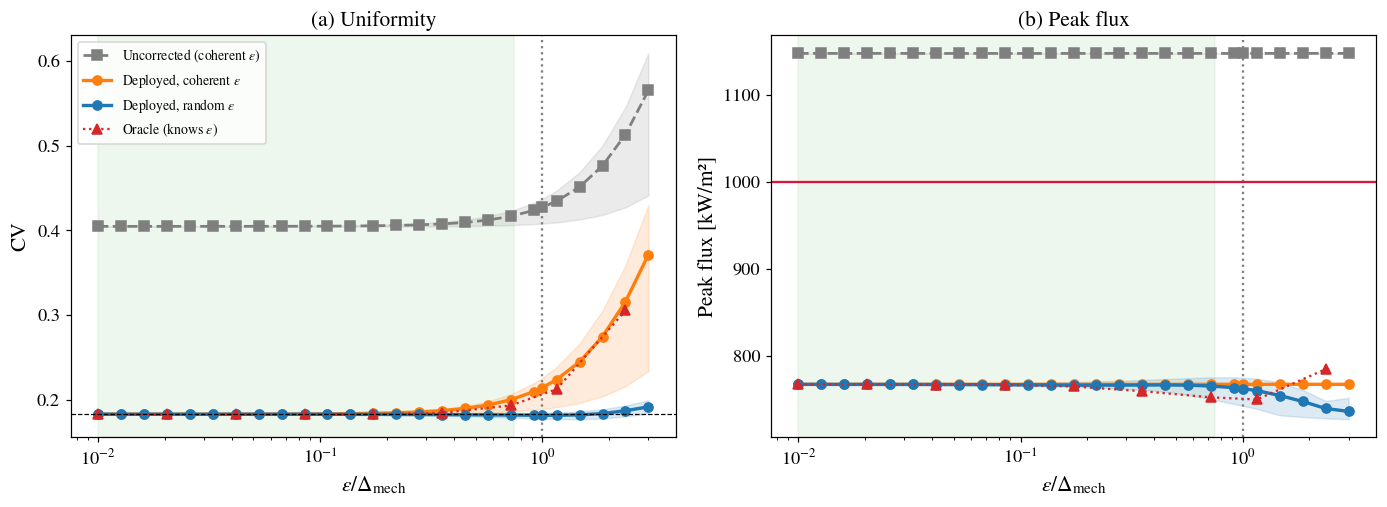

In [15]:
sw, ratios = sw_headline, ratios_headline
cv_design = R['qp']['cv']
R['decoupling'] = dict(summary=R['conditions']['equinox_noon']['decoupling'], ratios=ratios.tolist(), n_seeds=5,
                       sweep={m: {k: v.tolist() for k, v in d.items()} for m, d in sw.items()})
th = np.random.default_rng(100).uniform(0, 2*np.pi); oracle = []
for j in range(0, ratios.size, 3):
    em = ratios[j]*c.Dmech_mag; xs, ys = c.x0_mis + em*np.cos(th), c.y0_mis + em*np.sin(th)
    r = c.solve_qp(xs, ys, F_ref); lbj, ubj = c.bounds(ys)
    o = dict(ratio=float(ratios[j]), status=r['status'], n_pinned=int(np.sum(lbj[c.K:] == ubj[c.K:])),
             n_off_receiver=int(np.sum(np.abs(ys) > c.H_rec/2)),
             deployed_cv=float(sw['coherent']['cv_dep'][0, j]), deployed_peak=float(sw['coherent']['pk_dep'][0, j]))
    if r['dx'] is not None:
        o.update(cv=c.uniformity(r['F_true']), peak=r['peak'], lin_gap=r['lin_gap'], eta_int=100*c.interception(r['F_true']))
    oracle.append(o); print(o)
R['decoupling']['oracle'] = oracle; save_results()
print(R['decoupling']['summary'])

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12.8, 4.8))
thr = R['decoupling']['summary']['threshold_ratio']
def band(ax, Y, col, ls, labl, lw=1.8):
    Y = np.array(Y); ax.semilogx(ratios, Y.mean(0), ls, color=col, lw=lw, label=labl); ax.fill_between(ratios, Y.min(0), Y.max(0), color=col, alpha=0.15)
for ax, k in [(a1, 'cv'), (a2, 'pk')]:
    ax.axvspan(ratios[0], thr, color='C2', alpha=0.08); ax.axvline(1.0, color='grey', ls=':')
    band(ax, sw['coherent'][f'{k}_unc'], 'C7', 's--', r'Uncorrected (coherent $\varepsilon$)')
    band(ax, sw['coherent'][f'{k}_dep'], 'C1', 'o-', r'Deployed, coherent $\varepsilon$', 2.2)
    band(ax, sw['random'][f'{k}_dep'], 'C0', 'o-', r'Deployed, random $\varepsilon$', 2.2)
    o = [q for q in oracle if 'cv' in q]
    ax.semilogx([q['ratio'] for q in o], [q['cv' if k == 'cv' else 'peak'] for q in o], '^:', color='C3', label=r'Oracle (knows $\varepsilon$)')
    ax.set_xlabel(r'$\varepsilon/\Delta_{\mathrm{mech}}$')
a1.axhline(cv_design, color='k', ls='--', lw=0.8); a1.set_ylabel('CV'); a1.legend(fontsize=9, loc='upper left')
a2.axhline(1000, color='crimson'); a2.set_ylabel('Peak flux [kW/m²]')
a1.set_title('(a) Uniformity'); a2.set_title('(b) Peak flux'); fig.tight_layout(); savefig(fig, 'fig11_independence_R1.png'); plt.show()

## 11. Errors in the misalignment estimate (Reviewer 1, comment 6)

The correction is designed about an erroneous estimate of the displaced aim-points (random errors per
heliostat, or a 20 % bias in the drift magnitude) and evaluated on the true misalignment.

In [16]:
est = []
for kind, p, sd in [('random', s, k) for s in (0.1, 0.2, 0.5) for k in (1, 2)] + [('bias', 0.8, 0), ('bias', 1.2, 0)]:
    if kind == 'random':
        g_ = np.random.default_rng(500 + sd); xh, yh = c.x0_mis + p*g_.standard_normal(c.K), c.y0_mis + p*g_.standard_normal(c.K)
    else:
        xh, yh = c.x0_t + p*c.dmech_x, c.y0_t + p*c.dmech_y
    r = c.solve_qp(xh, yh, F_ref); rec = dict(kind=kind, param=p, seed=sd, status=r['status'])
    if r['dx'] is not None:
        rec.update(c.metrics(c.flux_map(c.x0_mis + r['dx'], np.clip(c.y0_mis + r['dy'], -c.H_rec/2, c.H_rec/2))))
    est.append(rec); print(rec)
R['estimation'] = est; save_results()

{'kind': 'random', 'param': 0.1, 'seed': 1, 'status': 'Solved', 'peak': 769.1855181986895, 'cv': 0.18311903610955418, 'eta_int': 83.79070232576143, 'P_int_MW': 168.84908719237916, 'mean': 602.1998176632286, 'max_ratio_to_afd': 0.7691855181986894}


{'kind': 'random', 'param': 0.1, 'seed': 2, 'status': 'Solved', 'peak': 766.8829345796514, 'cv': 0.18297335258869732, 'eta_int': 83.78494110640906, 'P_int_MW': 168.83747759129264, 'mean': 602.1584120520187, 'max_ratio_to_afd': 0.7668829345796514}


{'kind': 'random', 'param': 0.2, 'seed': 1, 'status': 'Solved', 'peak': 768.8976953500604, 'cv': 0.18416361362441702, 'eta_int': 83.84821975688513, 'P_int_MW': 168.96499224476946, 'mean': 602.6131927224385, 'max_ratio_to_afd': 0.7688976953500604}


{'kind': 'random', 'param': 0.2, 'seed': 2, 'status': 'Solved', 'peak': 765.9530800513777, 'cv': 0.1841381299843779, 'eta_int': 83.85856584957718, 'P_int_MW': 168.98584095779574, 'mean': 602.6875496016595, 'max_ratio_to_afd': 0.7659530800513777}


{'kind': 'random', 'param': 0.5, 'seed': 1, 'status': 'Solved', 'peak': 781.4468169972545, 'cv': 0.18917794841643173, 'eta_int': 84.10966152531184, 'P_int_MW': 169.49183117471645, 'mean': 604.4921623563725, 'max_ratio_to_afd': 0.7814468169972545}


{'kind': 'random', 'param': 0.5, 'seed': 2, 'status': 'Solved', 'peak': 769.9918303341256, 'cv': 0.18851122214648278, 'eta_int': 84.12522107393382, 'P_int_MW': 169.52318567478653, 'mean': 604.6039880969738, 'max_ratio_to_afd': 0.7699918303341255}


{'kind': 'bias', 'param': 0.8, 'seed': 0, 'status': 'Solved', 'peak': 772.9267700178964, 'cv': 0.18354948988897127, 'eta_int': 83.71735603050081, 'P_int_MW': 168.70128493437267, 'mean': 601.6726813055395, 'max_ratio_to_afd': 0.7729267700178963}


{'kind': 'bias', 'param': 1.2, 'seed': 0, 'status': 'Solved', 'peak': 761.7652164457865, 'cv': 0.18290297497212535, 'eta_int': 83.97825060940328, 'P_int_MW': 169.22702120675592, 'mean': 603.547718314223, 'max_ratio_to_afd': 0.7617652164457864}


## 12. Timing for online use (Reviewer 1, comment 9)

Split of the headline solve into sensitivity assembly, Hessian assembly and the interior-point solve, and the
effect of a looser solver tolerance.

In [17]:
R['timing'] = dict(headline=R['qp']['timing'])
c.C['qp_tol'] = 1e-3
r = c.solve_qp(c.x0_mis, c.y0_mis, F_ref); R['timing']['tol_1e-3'] = dict(timing=r['timing'], **qp_summary(c, r))
c.C['qp_tol'] = 1e-4
print(R['timing']); save_results()

{'headline': {'sensitivity': 0.024344444274902344, 'hessian': 0.4435420036315918, 'solve': 85.62198209762573, 'total': 88.14832186698914}, 'tol_1e-3': {'timing': {'sensitivity': 0.029494524002075195, 'hessian': 0.4983396530151367, 'solve': 85.69221925735474, 'total': 88.34741497039795}, 'status': 'Solved', 'feasible': True, 'time': 88.34741497039795, 'lin_gap': 0.057227049453413004, 'n_cap': 1160, 'step_sigma_min': 0.840872310296056, 'cap_exceed': 0.0, 'aim_y_max': 5.249804843623065, 'peak': 770.5323221517924, 'cv': 0.1829887736681077, 'eta_int': 83.8023916716175, 'P_int_MW': 168.8726427340191, 'mean': 602.2838284394572, 'max_ratio_to_afd': 0.7705323221517925}}


## 13. Input-parameter and focal-length sensitivity (Reviewer 2, comments 1 and 6)

Optical inputs of Sánchez-González et al. (2017) for the same plant (sunshape 2.51 mrad, reflectivity
0.88 x cleanliness 0.95), slope and tracking errors varied by 20 %, and a single focal length for all
heliostats instead of on-axis canting at the slant range.

In [18]:
variants = [('sigma_sun_2.51', dict(plant=dict(sigma_sun=2.51e-3))), ('reflectivity_0.836', dict(plant=dict(eta_ref=0.88*0.95))),
            ('slope_x0.8', dict(plant=dict(sigma_slope=0.8*2.6e-3))), ('slope_x1.2', dict(plant=dict(sigma_slope=1.2*2.6e-3))),
            ('tracking_x1.2', dict(plant=dict(sigma_t=1.2*2.1e-3))), ('single_focal_length', dict(focal='const', focal_m=float(np.median(c.D))))]
R['sensitivity'] = dict(baseline=dict(nominal=R['case']['nominal'], perturbed=R['case']['perturbed'], qp=R['qp'], f_aim=c.f_aim,
                                      sigma_HF=R['case']['sigma_HF']))
for name, kw in variants:
    ck = Case(psi_deg=RUN['psi_headline'], **kw)
    R['sensitivity'][name] = dict(f_aim=ck.f_aim, sigma_HF=[float(ck.sigma_HF.min()), float(ck.sigma_HF.max())],
                                  sigma_ast_mrad=[float(1e3*ck.sigma_ast.min()), float(1e3*ck.sigma_ast.max())],
                                  nominal=ck.metrics(ck.F_nominal), perturbed=ck.metrics(ck.F_perturbed),
                                  qp=qp_summary(ck, ck.solve_qp(ck.x0_mis, ck.y0_mis, uniform_ref(ck))))
    q = R['sensitivity'][name]
    print(f"{name:<22} uncorrected {q['perturbed']['peak']:.0f}  QP peak {q['qp'].get('peak', np.nan):.0f}  CV {q['qp'].get('cv', np.nan):.3f}  eta {q['qp'].get('eta_int', np.nan):.2f}")
save_results()

sigma_sun_2.51         uncorrected 1151  QP peak 769  CV 0.182  eta 83.96


reflectivity_0.836     uncorrected 1141  QP peak 746  CV 0.247  eta 87.18


slope_x0.8             uncorrected 1180  QP peak 781  CV 0.181  eta 85.41


slope_x1.2             uncorrected 1126  QP peak 760  CV 0.201  eta 82.60


tracking_x1.2          uncorrected 1143  QP peak 764  CV 0.185  eta 83.55


single_focal_length    uncorrected 1133  QP peak 722  CV 0.168  eta 79.93


## 14. Comparison with published values for the same plant (Reviewer 2, comment 6)

Table 1 of Sánchez-González et al. (2017) reports the peak flux and the interception factor of equatorial
aiming on the Gemasolar receiver at the summer solstice, computed with their validated optical model on the
surveyed field layout, including blocking and shading. The same quantities are computed here with our model,
their optical inputs and their DNI.

In [19]:
R['sg2017'] = {}
for hr, (dni, fmax_pub, fint_pub) in {12: (930, 1.208, 0.819), 9: (910, 1.157, 0.813), 7: (770, 0.880, 0.802)}.items():
    ck = Case(plant=dict(sigma_sun=2.51e-3, eta_ref=0.88*0.95), doy=172, solar_hour=float(hr), dni_override=dni/1000.0, psi_deg=RUN['psi_headline'])
    F_eq = ck.flux_map(ck.x0_t, np.zeros(ck.K))
    R['sg2017'][hr] = dict(dni=dni, published_peak_MW=fmax_pub, published_fint=fint_pub, model_peak_MW=float(F_eq.max()/1e3),
                           model_eta_int=ck.interception(F_eq), model_P_int_MW=float(F_eq.sum()*ck.pixel_area/1e3))
    print(hr, R['sg2017'][hr])
save_results()

12 {'dni': 930, 'published_peak_MW': 1.208, 'published_fint': 0.819, 'model_peak_MW': 1.2142390445002351, 'model_eta_int': 0.9298712149638597, 'model_P_int_MW': 168.89789109551873}


9 {'dni': 910, 'published_peak_MW': 1.157, 'published_fint': 0.813, 'model_peak_MW': 1.2868292331961495, 'model_eta_int': 0.9277218242289397, 'model_P_int_MW': 158.27046109135568}


7 {'dni': 770, 'published_peak_MW': 0.88, 'published_fint': 0.802, 'model_peak_MW': 1.1109045447913952, 'model_eta_int': 0.924822431613256, 'model_P_int_MW': 124.64226891521119}


### 14.1 Benchmark against a ray-tracing round-robin (Reviewer 2, comment 6)

Round B of the verification study of Wang et al. (2020), in which five Monte-Carlo ray tracers (SolTrace,
Tonatiuh, Tracer, Solstice, Heliosim) were run on identical cases: one ideally focused 10 m x 10 m heliostat
($f = D$, reflectivity 1, slope error 2 mrad, no tracking error) at four field positions and two sun positions,
a pillbox sun of 4.65 mrad half-angle, DNI = 1000 W/m², and a flat, north-facing 8 m x 6 m target centered at
(0, 0, 62) m, binned 100 x 100. The reference values are the published consensus of the five ray tracers, and
case A3.1 (on-axis, 500 m, 8 m x 8 m target) is included as a basic check. Our HFLCAL formulation is applied
unchanged: the pillbox sun enters through its standard deviation (half-angle/2), $\sigma_{bq}=2\sigma_{slope}$, and
the footprint is a circular Gaussian enlarged by $1/\cos\omega$ on the inclined target.

In [20]:
RR_HELIO = {1: (0.0, 46.5), 2: (0.0, 536.9), 3: (-324.3, 427.9), 4: (252.5, 118.1)}     # (x East, y North) [m], z = 0
RR_SUN = {1: (180.0, 12.0), 2: (76.0, 68.0)}                                            # (azimuth from North, zenith) [deg]
RR_PUBLISHED = {  # five-tool consensus of Wang et al. (2020), Round B, pillbox sun: (Q_irr, Q_abs [kW], peak [kW/m2])
    (1, 1): (97.66, 97.66, 68.67), (1, 2): (81.20, 56.75, 2.196), (1, 3): (79.90, 50.89, 1.735), (1, 4): (80.57, 62.51, 2.849),
    (2, 1): (76.34, 76.07, 8.862), (2, 2): (64.03, 45.45, 1.691), (2, 3): (83.82, 53.30, 1.801), (2, 4): (31.07, 11.51, 0.2823)}


def hflcal_flat_target(helio_xy, sun_az_zen, target=(0.0, 0.0, 62.0), width=8.0, height=6.0, nbin=100,
                       mirror=10.0, sun_halfangle=4.65e-3, slope=2.0e-3, dni=1.0):
    """HFLCAL flux of one ideally focused heliostat on a flat, north-facing target (single-heliostat test)."""
    az, zen = np.deg2rad(sun_az_zen[0]), np.deg2rad(sun_az_zen[1])
    Sv = np.array([np.sin(zen)*np.sin(az), np.sin(zen)*np.cos(az), np.cos(zen)])
    hpos = np.array([helio_xy[0], helio_xy[1], 0.0]); tvec = np.array(target) - hpos
    Dk = np.linalg.norm(tvec); Tu = tvec/Dk
    nrm = (Sv + Tu)/np.linalg.norm(Sv + Tu); cb = float(nrm @ Sv)
    Q_irr = dni*mirror**2*cb
    s_ast = mirror*abs(1.0 - cb)/(4*Dk)                      # f = D: H_t = w_s = d(1 - cos beta)
    cos_w = abs(Tu[1])                                       # target normal = +y (North)
    sig2 = Dk**2*((sun_halfangle/2)**2 + (2*slope)**2 + s_ast**2)/cos_w
    xb = (np.arange(nbin) + 0.5)/nbin*width - width/2; zb = (np.arange(nbin) + 0.5)/nbin*height - height/2
    Xb, Zb = np.meshgrid(xb, zb)
    F = Q_irr/(2*np.pi*sig2)*np.exp(-(Xb**2 + Zb**2)/(2*sig2))
    Q_abs = float(F.sum()*(width/nbin)*(height/nbin))
    return dict(Q_irr=Q_irr, Q_abs=Q_abs, peak=float(F.max()), sigma=float(np.sqrt(sig2)), beta_deg=float(np.degrees(np.arccos(cb))),
                D=float(Dk), cos_w=cos_w)


bench = []
for (sp_, hk), (qi, qa, pk) in RR_PUBLISHED.items():
    m = hflcal_flat_target(RR_HELIO[hk], RR_SUN[sp_])
    bench.append(dict(case=f'B1.{sp_}.{hk}', sun=('noon' if sp_ == 1 else 'morning'), beta_deg=m['beta_deg'], D=m['D'],
                      Q_irr_model=m['Q_irr'], Q_irr_pub=qi, Q_abs_model=m['Q_abs'], Q_abs_pub=qa, peak_model=m['peak'], peak_pub=pk,
                      d_peak_pct=100*(m['peak']/pk - 1), d_Qabs_pct=100*(m['Q_abs']/qa - 1)))
# case A3.1: on-axis heliostat (beta = 0), f = D = 500 m, 8 m x 8 m target; consensus Q_abs 83.94 kW, peak 2.925 kW/m2
sigA = 500*np.hypot(4.65e-3/2, 4e-3); xa = (np.arange(100) + 0.5)/100*8 - 4; Xa, Za = np.meshgrid(xa, xa)
FA = 100/(2*np.pi*sigA**2)*np.exp(-(Xa**2 + Za**2)/(2*sigA**2))
bench.append(dict(case='A3.1', sun='on-axis', beta_deg=0.0, D=500.0, Q_irr_model=100.0, Q_irr_pub=100.0,
                  Q_abs_model=float(FA.sum()*0.0064), Q_abs_pub=83.94, peak_model=float(FA.max()), peak_pub=2.925,
                  d_peak_pct=100*(FA.max()/2.925 - 1), d_Qabs_pct=100*(FA.sum()*0.0064/83.94 - 1)))
R['benchmark_wang2020'] = bench
print(f"{'case':<8}{'sun':<9}{'beta':>6}{'D':>7}{'Q_irr m/p':>15}{'Q_abs m/p':>16}{'peak m/p':>17}{'d_peak':>8}{'d_Qabs':>8}")
for b in bench:
    print(f"{b['case']:<8}{b['sun']:<9}{b['beta_deg']:>6.1f}{b['D']:>7.1f}{b['Q_irr_model']:>8.2f}/{b['Q_irr_pub']:<6.2f}"
          f"{b['Q_abs_model']:>9.2f}/{b['Q_abs_pub']:<6.2f}{b['peak_model']:>9.3f}/{b['peak_pub']:<7.3f}{b['d_peak_pct']:>7.1f}%{b['d_Qabs_pct']:>7.1f}%")
save_results()

case    sun        beta      D      Q_irr m/p       Q_abs m/p         peak m/p  d_peak  d_Qabs
B1.1.1  noon       12.4   77.5   97.65/97.66     97.65/97.66    70.242/68.670     2.3%   -0.0%
B1.1.2  noon       35.7  540.5   81.20/81.20     54.49/56.75     1.983/2.196     -9.7%   -4.0%
B1.1.3  noon       37.0  540.5   79.90/79.90     47.14/50.89     1.547/1.735    -10.8%   -7.4%
B1.1.4  noon       36.3  285.6   80.57/80.57     62.31/62.51     2.676/2.849     -6.1%   -0.3%
B1.2.1  morning    40.2   77.5   76.33/76.34     76.26/76.07    15.196/8.862     71.5%    0.3%
B1.2.2  morning    50.2  540.5   64.04/64.03     41.03/45.45     1.434/1.691    -15.2%   -9.7%
B1.2.3  morning    33.0  540.5   83.82/83.82     49.85/53.30     1.646/1.801     -8.6%   -6.5%
B1.2.4  morning    71.9  285.6   31.07/31.07     14.85/11.51     0.434/0.282     53.6%   29.0%
A3.1    on-axis     0.0  500.0  100.00/100.00    83.95/83.94     2.973/2.925      1.6%    0.0%


## 15. Annual clear-sky evaluation (Reviewer 2, comments 3 and 7; Reviewer 1, comment 3)

A grid of 12 representative days (the 21st of each month) and solar hours 07:00-17:00 with a clear-sky
(Hottel) DNI; each grid point represents one hour on every day of its month. These are clear-sky optical
estimates, not meteorological-year yields. At every grid point: the uncorrected misaligned plant, the
equinox-noon correction kept unchanged, and defocusing to the AFD. A correction re-solved at each condition
is computed at 15 sampled conditions (three days x five hours), interpolated over the year, and the
interpolation is checked against four direct solves at conditions not used for it.

annual energies [GWh_th] {'nominal': 461.26116010920794, 'perturbed': 457.417842703266, 'static': 447.8575193667699, 'defocus': 449.38099970188716, 'scheduled_qp': 448.044074755626}
hours {'total': 3529.0, 'perturbed_violation': 2799.0, 'static_violation': 0}
interpolation check [{'doy': 111, 'hour': 10.0, 'd_eta_direct': 3.685540268258663, 'd_eta_interp': 3.4649961895218078, 'peak': 711.5365458732307}, {'doy': 294, 'hour': 14.0, 'd_eta_direct': 2.7873102795863076, 'd_eta_interp': 2.507907145026272, 'peak': 718.6388592698618}, {'doy': 52, 'hour': 11.0, 'd_eta_direct': 3.6657415871490002, 'd_eta_interp': 2.871400275604283, 'peak': 722.5331482109448}, {'doy': 233, 'hour': 15.0, 'd_eta_direct': 2.881702824273077, 'd_eta_interp': 2.6269079225930447, 'peak': 699.4580967016034}]


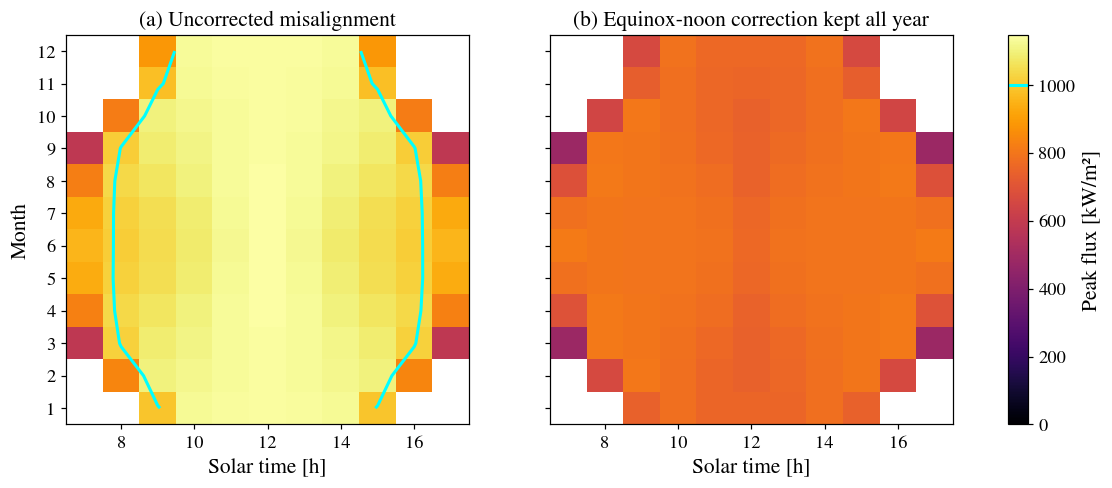

In [21]:
if RUN['annual']:
    from scipy.interpolate import RegularGridInterpolator
    MONTH_DAYS = [31, 28, 31, 30, 31, 30, 31, 31, 30, 31, 30, 31]
    MID_DOY = [21, 52, 80, 111, 141, 172, 202, 233, 264, 294, 325, 355]
    grid = []
    for m_, doy in enumerate(MID_DOY):
        for hr in np.arange(7.0, 17.01, 1.0):
            el = np.degrees(np.arcsin(sun_vector(doy, hr, GEMASOLAR['phi_lat'])[0][2]))
            if el < 10: continue
            dni = hottel_dni(doy, el)
            ck = Case(psi_deg=RUN['psi_headline'], doy=doy, solar_hour=hr, dni_override=dni)
            F_static = ck.flux_map(ck.x0_mis + dx0, np.clip(ck.y0_mis + dy0, -ck.H_rec/2, ck.H_rec/2))
            n_rm, F_def = defocus(ck, ck.x0_mis, ck.y0_mis, ck.F_max_scalar)
            grid.append(dict(month=m_ + 1, doy=doy, hour=hr, elevation=float(el), dni=dni, weight_h=float(MONTH_DAYS[m_]),
                             P_field=float(ck.P_H.sum()/1e3), declination=float(ck.declination), nominal=ck.metrics(ck.F_nominal),
                             perturbed=ck.metrics(ck.F_perturbed), static=ck.metrics(F_static), defocus=dict(n_removed=n_rm, **ck.metrics(F_def))))

    def qp_at(doy, hr):
        el = np.degrees(np.arcsin(sun_vector(doy, hr, GEMASOLAR['phi_lat'])[0][2])); dni = hottel_dni(doy, el)
        ck = Case(psi_deg=RUN['psi_headline'], doy=doy, solar_hour=hr, dni_override=dni)
        srow = qp_summary(ck, ck.solve_qp(ck.x0_mis, ck.y0_mis, uniform_ref(ck)))
        srow.update(doy=doy, hour=hr, dni=dni, declination=float(ck.declination), eta_nominal=100*ck.interception(ck.F_nominal))
        srow['d_eta'] = srow['eta_nominal'] - srow['eta_int'] if srow['feasible'] else np.nan
        return srow
    samp_days, samp_hours = [355, 80, 172], [8.0, 10.0, 12.0, 14.0, 16.0]
    samples = [qp_at(d, h) for d in samp_days for h in samp_hours]
    D_eta = np.array([[samples[i*5 + j]['d_eta'] for j in range(5)] for i in range(3)])
    interp = RegularGridInterpolator((np.array([samples[i*5]['declination'] for i in range(3)]), np.array(samp_hours)), D_eta,
                                     bounds_error=False, fill_value=None)
    validation = []
    for d, h in [(111, 10.0), (294, 14.0), (52, 11.0), (233, 15.0)]:
        s_ = qp_at(d, h); validation.append(dict(doy=d, hour=h, d_eta_direct=s_['d_eta'],
                                                 d_eta_interp=float(interp([[s_['declination'], h]])[0]), peak=s_.get('peak')))
    for g_ in grid:
        g_['scheduled_d_eta'] = float(interp([[g_['declination'], g_['hour']]])[0])
    E = lambda key: sum(g_[key]['P_int_MW']*g_['weight_h'] for g_ in grid)/1e3
    R['annual'] = dict(
        grid=grid, samples=samples, validation=validation,
        E_GWh_th=dict(nominal=E('nominal'), perturbed=E('perturbed'), static=E('static'), defocus=E('defocus'),
                      scheduled_qp=sum((g_['nominal']['P_int_MW'] - g_['scheduled_d_eta']/100*g_['P_field'])*g_['weight_h'] for g_ in grid)/1e3),
        hours=dict(total=sum(g_['weight_h'] for g_ in grid),
                   perturbed_violation=sum(g_['weight_h'] for g_ in grid if g_['perturbed']['peak'] > 1000),
                   static_violation=sum(g_['weight_h'] for g_ in grid if g_['static']['peak'] > 1000)),
        sample_peaks_max=float(np.nanmax([s_.get('peak', np.nan) for s_ in samples])))
    save_results()
    print('annual energies [GWh_th]', R['annual']['E_GWh_th']); print('hours', R['annual']['hours'])
    print('interpolation check', validation)

    months = sorted(set(g_['month'] for g_ in grid)); hours = sorted(set(g_['hour'] for g_ in grid))
    M = np.full((len(months), len(hours)), np.nan); Sst = np.full_like(M, np.nan)
    for g_ in grid:
        M[months.index(g_['month']), hours.index(g_['hour'])] = g_['perturbed']['peak']
        Sst[months.index(g_['month']), hours.index(g_['hour'])] = g_['static']['peak']
    fig, axs = plt.subplots(1, 2, figsize=(13, 4.6), sharey=True); vmax = np.nanmax(M)
    for ax, Z, t in [(axs[0], M, '(a) Uncorrected misalignment'), (axs[1], Sst, '(b) Equinox-noon correction kept all year')]:
        im = ax.imshow(Z, origin='lower', aspect='auto', cmap='inferno', vmin=0, vmax=vmax,
                       extent=[hours[0] - 0.5, hours[-1] + 0.5, months[0] - 0.5, months[-1] + 0.5])
        if np.nanmax(Z) > 1000: ax.contour(np.array(hours), np.array(months), Z, levels=[1000], colors='cyan', linewidths=2)
        ax.set_title(t); ax.set_xlabel('Solar time [h]')
    axs[0].set_ylabel('Month'); axs[0].set_yticks(np.arange(1, 13))
    cb = fig.colorbar(im, ax=axs, label='Peak flux [kW/m²]'); cb.ax.axhline(1000, color='cyan', lw=2)
    savefig(fig, 'fig_annual_R1.png'); plt.show()

## 16. Scaling of the baselines (Reviewer 1, comment 4)

Finer groupings up to a per-heliostat search ($G = K = 2650$), a finer $7\times7$ grid, and budgets of 3 and 10
times the QP time; five seeds at 1x and 3x, three at 10x. The per-heliostat tensor takes 4.3 GB.

ACO G=120 grid=5 1x seed 1: gens 694 peak 996.4 CV 0.3624


GA G=120 grid=5 1x seed 1: gens 53 peak 963.1 CV 0.3312


ACO G=120 grid=5 1x seed 2: gens 653 peak 999.9 CV 0.3567


GA G=120 grid=5 1x seed 2: gens 53 peak 976.3 CV 0.3391


ACO G=120 grid=5 1x seed 3: gens 670 peak 992.3 CV 0.3555


...

GA G=480 grid=5 10x seed 1: gens 110 peak 998.5 CV 0.3646


ACO G=480 grid=5 10x seed 2: gens 1852 peak 997.7 CV 0.3648


GA G=480 grid=5 10x seed 2: gens 116 peak 979.7 CV 0.3542


ACO G=480 grid=5 10x seed 3: gens 1861 peak 991.6 CV 0.3625


GA G=480 grid=5 10x seed 3: gens 113 peak 980.7 CV 0.3537


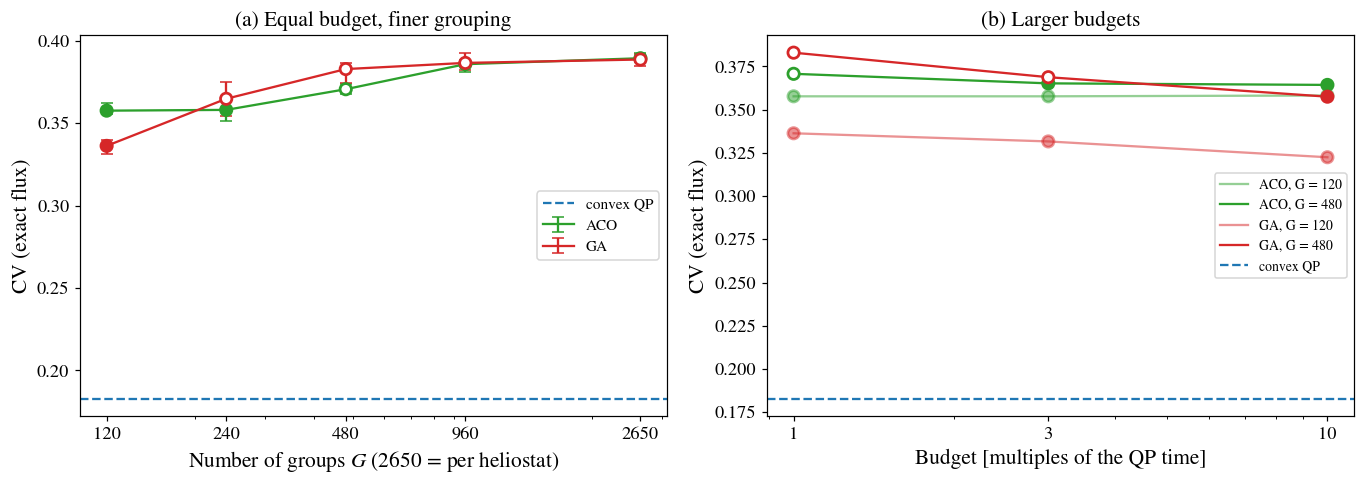

In [22]:
if RUN['scaling']:
    configs = [(G, 5, 1) for G in (120, 240, 480, 960, 2650)] + [(120, 7, 1), (120, 5, 3), (480, 5, 3), (120, 5, 10), (480, 5, 10)]
    scal = []
    for G, grid, bx in configs:
        grp, Gr = c.make_groups(G, seed=1)
        t0 = time.time(); ctb, cnd, _, gxc_, gyc_ = c.build_group_contrib(grp, Gr, grid); t_build = time.time() - t0
        seeds = RUN['seeds'] if bx < 10 else RUN['seeds'][:3]
        for s in seeds:
            for name in ('ACO', 'GA'):
                if name == 'ACO':
                    best, traj, gens = aco(c, ctb, bx*budget, F_ref, c.F_max_scalar, seed=s)
                else:
                    best, traj, gens = ga(c, ctb, gxc_, gyc_, bx*budget, F_ref, c.F_max_scalar, seed=s)
                m = c.metrics(evaluate_assignment(c, cnd, grp, best))
                m.update(algo=name, G=Gr, grid=grid, budget_x=bx, seed=s, generations=gens, t_build=t_build)
                scal.append(m); print(f"{name} G={Gr} grid={grid} {bx}x seed {s}: gens {gens} peak {m['peak']:.1f} CV {m['cv']:.4f}")
        del ctb
        R['scaling'] = scal; save_results()

    fig, (a1, a2) = plt.subplots(1, 2, figsize=(12.6, 4.6))
    for name, col in [('ACO', 'C2'), ('GA', 'C3')]:
        rows = [r for r in scal if r['algo'] == name and r['budget_x'] == 1 and r['grid'] == 5]
        Gs = sorted(set(r['G'] for r in rows)); cvs = [[r['cv'] for r in rows if r['G'] == G] for G in Gs]
        feas = [all(r['peak'] <= 1000 for r in rows if r['G'] == G) for G in Gs]; mcv = np.array([np.mean(v) for v in cvs])
        a1.errorbar(Gs, mcv, yerr=[mcv - [min(v) for v in cvs], [max(v) for v in cvs] - mcv], fmt='-', color=col, capsize=4, label=name)
        a1.scatter(Gs, mcv, s=55, zorder=3, color=[col if f else 'white' for f in feas], edgecolors=col, linewidths=1.8)
        for G, alpha in ((120, 0.5), (480, 1.0)):
            rb = [r for r in scal if r['algo'] == name and r['G'] == G and r['grid'] == 5]
            bxs = sorted(set(r['budget_x'] for r in rb)); m = [np.mean([r['cv'] for r in rb if r['budget_x'] == b]) for b in bxs]
            f = [all(r['peak'] <= 1000 for r in rb if r['budget_x'] == b) for b in bxs]
            a2.plot(bxs, m, '-', color=col, alpha=alpha, label=f'{name}, G = {G}')
            a2.scatter(bxs, m, s=55, zorder=3, color=[col if q else 'white' for q in f], edgecolors=col, alpha=alpha, linewidths=1.8)
    for ax in (a1, a2):
        ax.axhline(R['qp']['cv'], color='C0', ls='--', label='convex QP'); ax.set_xscale('log'); ax.set_ylabel('CV (exact flux)')
        ax.xaxis.set_minor_formatter(plt.NullFormatter())
    a1.set_xticks([120, 240, 480, 960, 2650]); a1.set_xticklabels(['120', '240', '480', '960', '2650'])
    a2.set_xticks([1, 3, 10]); a2.set_xticklabels(['1', '3', '10'])
    a1.set_xlabel('Number of groups $G$ (2650 = per heliostat)'); a1.set_title('(a) Equal budget, finer grouping'); a1.legend(fontsize=10)
    a2.set_xlabel('Budget [multiples of the QP time]'); a2.set_title('(b) Larger budgets'); a2.legend(fontsize=9)
    fig.tight_layout(); savefig(fig, 'fig_scaling_R1.png'); plt.show()

## Modeling assumptions and limitations

1. **Field reconstruction.** Exact as-built heliostat coordinates of Gemasolar are not public; the field is a
   radial-staggered ring reconstruction with the correct heliostat count, mirror area, radial extent and tower
   height. Absolute flux values carry the uncertainty of this reconstruction; the comparison between methods,
   which all run on the identical field, does not.
2. **Blocking and shading** are neglected ($f_{bs}=1$), an optimistic bias on absolute power (Section 14).
3. **Footprint curvature.** HFLCAL places one circular Gaussian per heliostat on the unwrapped surface.
4. **AFD.** A scalar 1000 kW/m² in the main study; Section 7 uses the flow-path profile of
   Sánchez-González et al. (2017), scaled to this plant. A receiver thermal model is not coupled.
5. **Operating points.** Fixed DNI of 0.95 kW/m² except in Section 15 (clear sky, not meteorological data).
6. **Baselines** are budgeted in wall-clock time and grouped; Section 16 shows how this affects them.

In [23]:
save_results()
print('results written to results_R1.json; figures in', FIGDIR)

results written to results_R1.json; figures in figures
